# Chicago Traffic Crash Analysis (2018–2025)
## Notebook 2: Analysis, findings and recommendations

**Author:** Armon Saeedvafa
**Date:** November 2026

This notebook uses the datasets prepared in [Notebook 1](01_data_collection_and_cleaning.ipynb). Run Notebook 1 first.

## 1. Executive summary

Chicago police recorded **877,919 traffic crashes** from 2018 through 2025. Crash counts show *where* crashes happen, but busy places naturally have more crashes. This project combines crash and injury records with traffic volumes and mobility data to estimate **risk per mile driven**, and identifies the community areas, times, intersections and street corridors that transportation safety planners should investigate first.

### Key findings

1. **The busiest time to drive is also the riskiest.** On weekdays from 3 to 7 p.m., about **2.88 of every 10,000 ten-mile drives** involve a reported crash, more than twice the overnight rate (1.35) and well above the city average (1.89).
2. **High crash counts and high risk are in different places.** Austin, the Near West Side and the Near North Side have the most crashes. Per mile driven, **West Garfield Park** is the most dangerous area (22.88 crashes per million vehicle-miles, about twice the citywide 11.19), followed by the Near West Side, Chatham, Greater Grand Crossing and Rogers Park. Lake View and Lincoln Park have many crashes mainly because they carry a lot of traffic.
3. **Serious injuries are concentrated on the West and South Sides.** Citywide, 1.83% of crashes involve a death or incapacitating injury. The share reaches 2.89% in West Garfield Park and about 2.8% in East Garfield Park and Washington Park. Relative to traffic, West Garfield Park's serious-crash rate is about three times the citywide level.
4. **Greater Grand Crossing is the only area in the top 15 on all five measures:** total crashes, serious crashes, serious-outcome share, crashes per resident and crashes per mile driven.
5. **Crashes cluster at intersections and a few corridors.** 62.6% of crashes happen at intersections. The Lake Shore Drive curve at Oak Street has the most crashes of any intersection (1,059), and the blocks where the Dan Ryan Expressway meets the street grid make up 5 of the 15 highest-count half-mile corridors.
6. **Injuries are becoming a larger share of crashes.** Total crashes have been flat since 2021, but the share involving injuries rose from about 15% in the summers of 2018–2019 to 18–19% in 2024–2025.

### Key visuals

**Estimated chance that a 10-mile drive involves a reported crash, by weekday and hour**

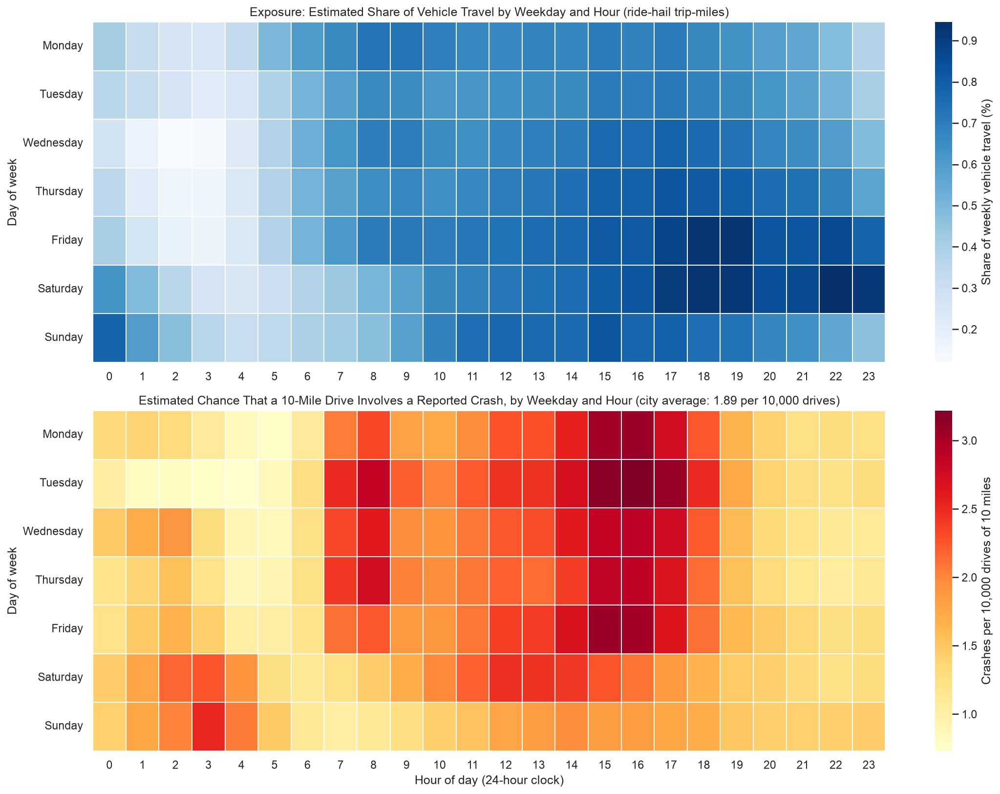

**Most dangerous community areas per mile driven**

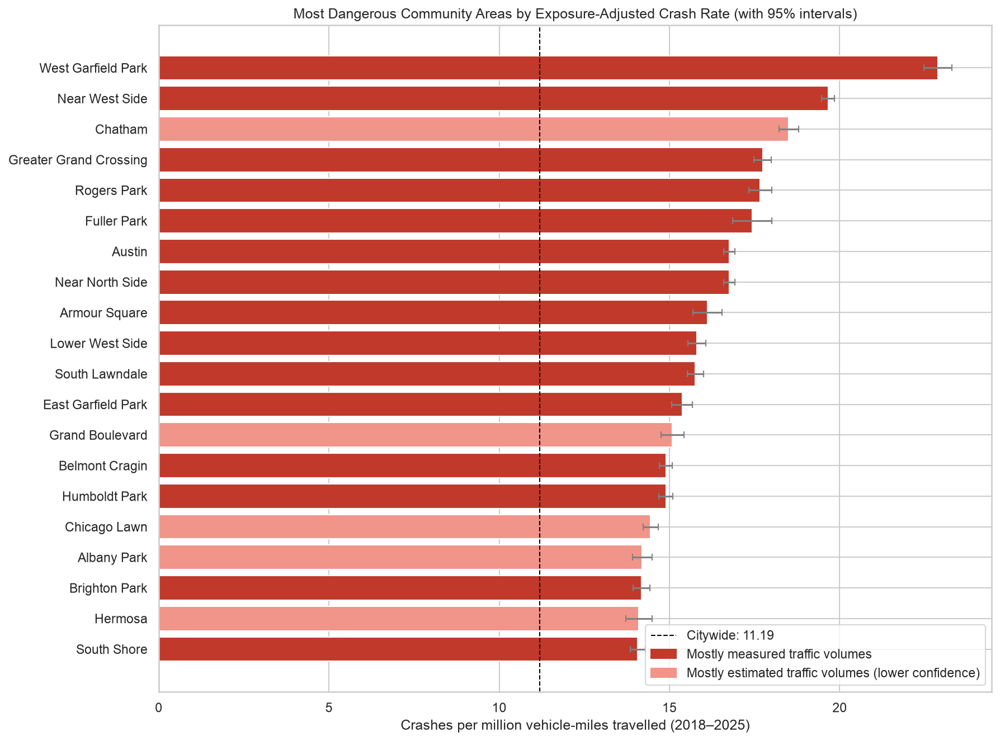

**Crash density across Chicago ([open the interactive map](https://08armon.github.io/chicago-traffic-crash-analysis/maps/crash_density_and_risk.html))**

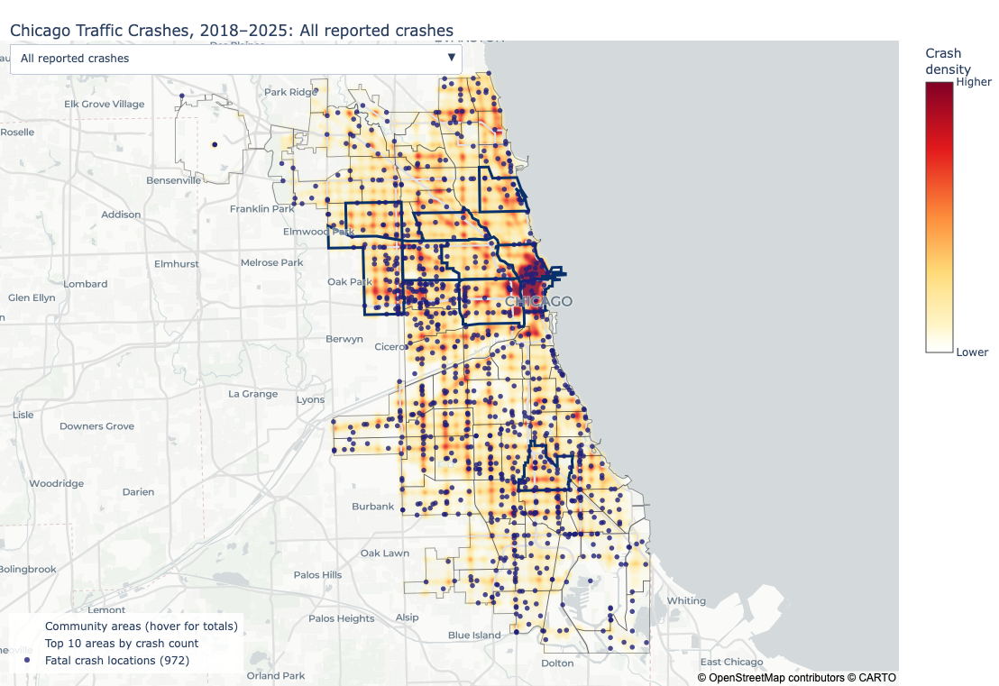

In [20]:
# Show the key visuals from the project's images/ folder (the chart cells below save fresh copies there).
from pathlib import Path
from IPython.display import Image, Markdown, display

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
KEY_VISUALS = [
    ("per_drive_risk_heatmap.png",
     "Estimated chance that a 10-mile drive involves a reported crash, by weekday and hour"),
    ("dangerousness_bar.png", "Most dangerous community areas per mile driven"),
    ("map_crash_density_and_risk.png",
     "Crash density across Chicago ([open the interactive map](https://08armon.github.io/chicago-traffic-crash-analysis/maps/crash_density_and_risk.html))"),
]
for file_name, caption in KEY_VISUALS:
    display(Markdown(f"**{caption}**"))
    image_path = PROJECT_ROOT / "images" / file_name
    if image_path.exists():
        display(Image(filename=str(image_path), width=900))
    else:
        display(Markdown(f"*Image not found: `{image_path}`. Run the chart cells below to create it.*"))

### Top three recommendations (candidate interventions for evaluation)

1. **West Side arterials (West Garfield Park, East Garfield Park, Austin):** area-wide speed management (speed cameras and speed-feedback signs), evaluation of road diets on the four-lane sections of Cicero Avenue, Central Avenue and Pulaski Road, and safer pedestrian crossings at signals and bus stops.
2. **Dan Ryan Expressway interchanges (87th, 79th and 63rd Streets, Garfield Boulevard, Cermak and Roosevelt Roads):** protected left-turn phases, leading pedestrian intervals and refuge islands at the ramp signals, especially on walking routes to Red Line stations.
3. **Lake Shore Drive curves at Oak Street and 57th Street:** speed management on the curves, high-friction pavement and better curve warning and lane markings.

Section 9 lists all ten recommendations with their evidence and the agencies that would lead them. These are candidates for engineering review, not proven fixes: the analysis shows where and when to look, not what caused each crash.

### How reliable are these estimates?

About 59% of the estimated vehicle-miles come from measured traffic counts; the rest are estimated from typical volumes for each road type. The hour-by-hour travel pattern comes from a sample of ride-hail trips. Area-level results rest on large numbers of crashes and are stable. Rates for individual intersections and corridors are shown only when they rest on at least 30 crashes and mostly measured traffic, and locations right next to a much busier road are left out of the rate rankings (see Section 4.2).

### Research questions

1. How do reported crash counts vary by weekday, hour, and month?
2. Which Chicago community areas have the highest numbers of reported crashes?
3. Which community areas have the greatest numbers and proportions of crashes involving serious outcomes?
4. How do community-area comparisons change when crash counts are adjusted for population?
5. How do comparisons change when crashes are adjusted for road-user exposure (vehicle-miles travelled, entering traffic, transit boardings and bike-share trips)? Which areas and times carry the highest risk per trip?
6. Which specific intersections and street corridors have the most crashes, the most serious outcomes, and the highest crash rates relative to traffic?

**Intended audience:** Chicago Department of Transportation (CDOT) safety planners and community-area decision-makers.

## 2. Setup

The setup cell loads the libraries and the datasets prepared in Notebook 1. It also defines two small helpers: `save_chart` saves each chart to `images/` (used by the README), and `save_map` saves each interactive map as a web page in `docs/maps/` (published with GitHub Pages). Re-running this notebook therefore keeps the README and the project website in step with the analysis.

In [21]:
# Setup: libraries, display options, constants, project folders and the prepared data from Notebook 1.
import re
from pathlib import Path

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import plotly.graph_objects as go
import plotly.io as pio
import seaborn as sns
from IPython.display import display
from matplotlib.patches import Patch

pd.set_option("display.max_columns", 100)
pd.set_option("display.width", 140)
sns.set_theme(style="whitegrid")

# Show each interactive map in Plotly's native format (Jupyter) and as self-contained HTML (Google Colab).
pio.renderers.default = "plotly_mimetype+colab"

# Study period and map projection (the same values as in Notebook 1).
START_YEAR = 2018
END_YEAR = 2025
N_YEARS = END_YEAR - START_YEAR + 1
STUDY_DAYS = (pd.Timestamp(f"{END_YEAR + 1}-01-01") - pd.Timestamp(f"{START_YEAR}-01-01")).days
PROJECTED_CRS = "EPSG:26971"  # NAD83 / Illinois East (metres), used for distances

# Project folders. The notebook can be run from the notebooks/ folder or from the project's main folder.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROCESSED_DIR = PROJECT_ROOT / "data" / "processed"
IMAGE_DIR = PROJECT_ROOT / "images"       # static charts shown in the README
MAP_DIR = PROJECT_ROOT / "docs" / "maps"  # interactive maps published with GitHub Pages
IMAGE_DIR.mkdir(exist_ok=True)
MAP_DIR.mkdir(parents=True, exist_ok=True)

# Load the datasets prepared in Notebook 1.
prepared = pd.read_pickle(PROCESSED_DIR / "prepared_data.pkl")
crash_enriched = prepared["crash_enriched"]
df_geo = prepared["df_geo"]
road, midpoints, idot_aadt = prepared["road"], prepared["midpoints"], prepared["idot_aadt"]
tnp, l_stations, bus_stops = prepared["tnp"], prepared["l_stations"], prepared["bus_stops"]
divvy_stations, divvy_hourly = prepared["divvy_stations"], prepared["divvy_hourly"]
community_areas, population = prepared["community_areas"], prepared["population"]
print(f"Loaded {len(crash_enriched):,} crashes ({len(df_geo):,} with valid coordinates) "
      f"and {len(road):,} street blocks.")


def save_chart(name):
    """Save the current chart to images/<name>.png, then display it."""
    plt.savefig(IMAGE_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.show()


def save_map(fig, name, page_title):
    """Save an interactive map to docs/maps/<name>.html (a standalone web page), then display it."""
    path = MAP_DIR / f"{name}.html"
    fig.write_html(path, include_plotlyjs="cdn")  # the page loads Plotly from the internet, which keeps it small
    page = path.read_text(encoding="utf-8").replace(
        "<head>", f'<head><title>{page_title}</title>'
                  '<meta name="viewport" content="width=device-width, initial-scale=1">', 1)
    path.write_text(page, encoding="utf-8")
    fig.show()

Loaded 877,919 crashes (870,789 with valid coordinates) and 52,767 street blocks.


## 3. When do crashes occur?

This section answers the first research question. The weekday/hour heatmap describes when reported crashes are most frequent. The monthly trend chart shows whether overall crash counts and the proportion of crashes involving reported injuries change over time.

These are counts of reported crashes, not exposure-adjusted risk estimates.

### 3.1 Weekday and hour pattern

The heatmap shows the number of reported crashes in each weekday/hour cell. It describes when crashes are most frequent, not the probability that a particular person will crash.

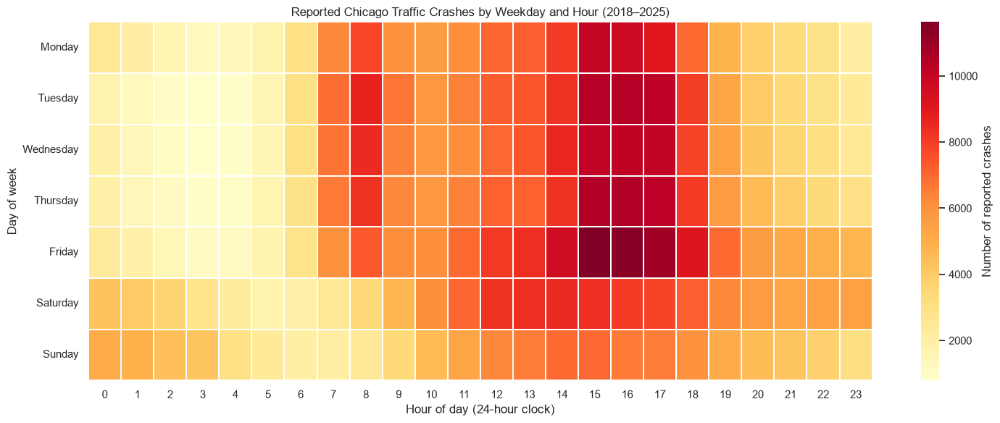

In [22]:
# Count reported crashes in each weekday/hour cell and draw them as a heatmap.
days_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
temporal = crash_enriched.assign(hour=crash_enriched["crash_date"].dt.hour,
                           day_of_week=pd.Categorical(crash_enriched["crash_date"].dt.day_name(),
                                                      categories=days_order, ordered=True))
crash_counts = (temporal.groupby(["day_of_week", "hour"], observed=False)["crash_record_id"].nunique()
                .unstack(fill_value=0).reindex(index=days_order, columns=range(24), fill_value=0))

fig, ax = plt.subplots(figsize=(15, 6))
sns.heatmap(crash_counts, cmap="YlOrRd", linewidths=0.2, cbar_kws={"label": "Number of reported crashes"}, ax=ax)
ax.set(title="Reported Chicago Traffic Crashes by Weekday and Hour (2018–2025)",
       xlabel="Hour of day (24-hour clock)", ylabel="Day of week")
plt.tight_layout()
save_chart("weekday_hour_counts")

**Interpretation:**

- **Highest-count combinations:** The weekday afternoon commute window dominates. **Friday 3–5 p.m. (hours 15, 16 and 17)** are the darkest cells in the heatmap, at roughly 11,000–11,500 reported crashes each over 2018–2025. That is about 1.3% of all crashes per cell, compared with an average of about 0.6% for any one of the 168 day/hour cells. **Tuesday–Thursday 3–5 p.m.** follow closely (roughly 10,000–10,500 each), then **Monday 3–5 p.m.**
- **Secondary peaks:** A smaller weekday morning peak appears at **8 a.m.**, strongest Tuesday–Thursday (roughly 8,000–9,000). On weekends there is no sharp commute peak. Saturday crashes build to a broad midday plateau (about noon–3 p.m., roughly 8,000–8,500), and Sunday is lower throughout.
- **Late-night weekend pattern:** Counts in the **early hours of Saturday and Sunday (midnight–2 a.m.)** are about twice the counts for the same hours on weekdays (roughly 4,500–5,000 versus about 2,000). The fewest reported crashes are on weekdays between 2 and 5 a.m.
- **Counts versus risk per drive:** These are counts, not rates. Section 3.3 divides them by the estimated amount of travel in each hour. The weekday afternoon peak is the riskiest time per drive as well as the busiest: about 2.9 crash involvements per 10,000 ten-mile drives on weekdays from 3 to 6 p.m., against a city average of 1.9. By contrast, the weekend late-night excess is mostly explained by how much travel happens then. Per drive, Saturday and Sunday from midnight to 4 a.m. average about 1.9 per 10,000, close to the city average. The hourly travel pattern comes from ride-hail trips, which over-represent late-night travel, so late-night risk per drive may be somewhat understated.

### 3.2 Monthly crash and injury trends

The upper chart compares all reported crashes with crashes whose crash-level injury total is greater than zero. The lower chart shows injury crashes as a percentage of crashes with known `injuries_total`. Missing injury totals are excluded from the percentage denominator rather than assumed to mean no injuries.

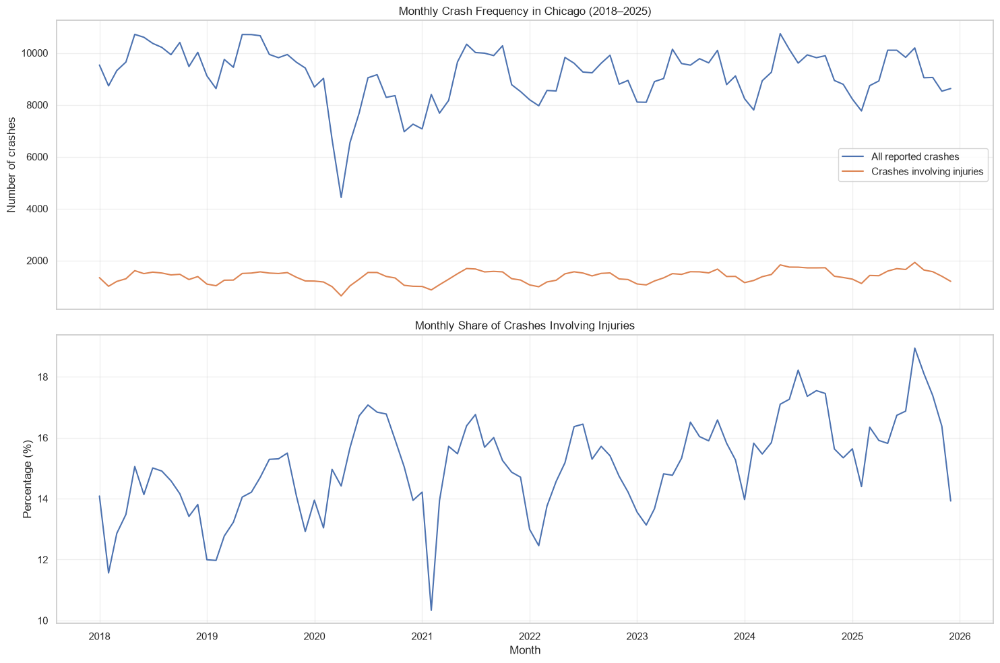

In [23]:
# Monthly totals: all crashes, crashes with injuries, and the injury share among crashes with known injury data.
injury_known = crash_enriched["injuries_total"].notna()
monthly = (crash_enriched.assign(month=crash_enriched["crash_date"].dt.to_period("M").dt.to_timestamp(),
                           known=injury_known, injury_crash=injury_known & crash_enriched["injuries_total"].gt(0))
           .groupby("month").agg(total_crashes=("crash_record_id", "nunique"),
                                 crashes_with_known_injury_data=("known", "sum"),
                                 injury_crashes=("injury_crash", "sum"))
           .reindex(pd.date_range(f"{START_YEAR}-01-01", f"{END_YEAR}-12-01", freq="MS")))
monthly["injury_percentage"] = (monthly["injury_crashes"]
                                / monthly["crashes_with_known_injury_data"].replace(0, np.nan) * 100)

# Plot monthly crash counts (top) and the monthly injury share (bottom).
fig, axes = plt.subplots(2, 1, figsize=(15, 10), sharex=True)
axes[0].plot(monthly.index, monthly["total_crashes"], label="All reported crashes")
axes[0].plot(monthly.index, monthly["injury_crashes"], label="Crashes involving injuries")
axes[0].set(title="Monthly Crash Frequency in Chicago (2018–2025)", ylabel="Number of crashes")
axes[0].legend()
axes[1].plot(monthly.index, monthly["injury_percentage"])
axes[1].set(title="Monthly Share of Crashes Involving Injuries", ylabel="Percentage (%)", xlabel="Month")
for ax in axes:
    ax.grid(alpha=0.3)
plt.tight_layout()
save_chart("monthly_trends")

**Interpretation:**

- **Seasonal pattern:** Every year shows the same cycle. Monthly crash counts are lowest in late winter (February is usually the low point, at roughly 7,800–8,700) and highest from late spring through early fall (May–October, often 9,800–10,700). The injury-crash share follows the same seasonal shape: lowest in January–February and highest in summer.
- **Unusual period (2020–early 2021):** Total crashes fell abruptly in spring 2020. **April 2020 (about 4,400 crashes)** is the lowest month in the series, about half of a typical spring month. Counts recovered to about 9,000 by mid-2020 but stayed below pre-2020 levels through February 2021 (about 7,000–7,300 per month in late 2020 and early 2021). The timing coincides with the COVID-19 period. **February 2021** is also an isolated low in the injury share (about 10.3%, the lowest value in the series).
- **Sustained trend in counts:** After 2021, monthly totals returned to roughly the 2018–2019 range (about 8,000–10,500) with no clear sustained upward or downward trend.
- **Sustained trend in injury share:** The percentage of crashes involving injuries shows a **gradual upward drift**. Summer peaks rose from about 15% in 2018–2019 to about 16.5–17% in 2020–2023 and about 18–19% in 2024–2025, and winter lows rose from about 11.5–12% to about 14%. The injury-crash count line also sits higher in 2024–2025 (summer months of roughly 1,750–1,950 versus about 1,500–1,600 in 2018–2019).
- **Do the percentage and the counts move together?**
  - *Seasonally, yes:* both rise in summer and fall in winter.
  - *In 2020, no:* total crashes dropped sharply, but the injury share **rose** to about 17% by mid-2020, because crashes with injuries fell less than other crashes.
  - *In 2024–2025:* total crashes were similar to earlier years while the injury share reached its highest levels, so the higher share comes from more injury crashes, not from fewer crashes overall.

### 3.3 Exposure-adjusted risk by weekday and hour

Section 3.1 showed *when* the most crashes are reported. That partly reflects *when the most people are driving*. This section divides crashes by an estimate of how much driving happens in each weekday/hour cell:

- **Exposure:** total VMT (Notebook 1, Section 3.6) × the share of weekly vehicle travel in that hour, estimated from ride-hail trip-miles.
- **Crash rate:** crashes ÷ VMT.
- **Per-drive probability:** the estimated chance that a 10-mile drive involves a reported crash, = 1 − exp(−crash rate × vehicles per crash × 10 miles), shown per 10,000 drives. Multiplying by the average number of vehicles per crash converts crashes into per-vehicle (per-driver) involvements.

A second chart compares relative risk by hour for drivers (crashes per vehicle-mile) and cyclists (cyclist-involved crashes per bike-share trip, 2018–2019).

These estimates are only as good as the exposure proxy. Ride-hail travel over-represents evenings and weekends compared with all traffic, so late-night risk is more likely to be *understated* than overstated.

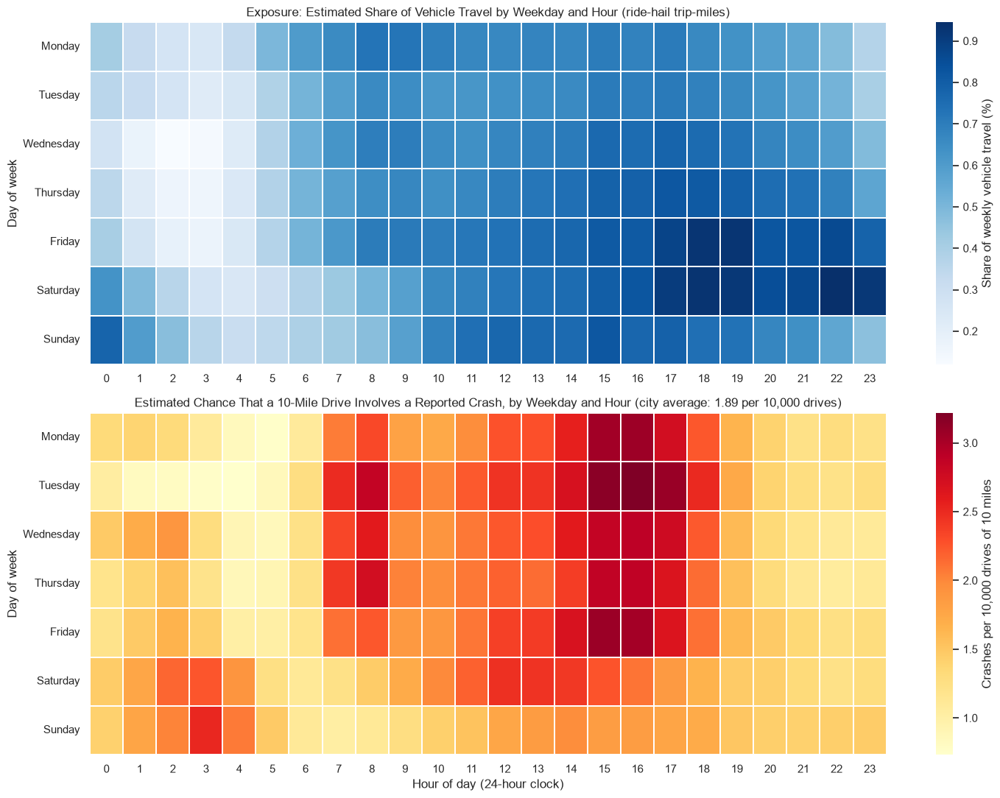

Highest exposure-adjusted risk (weekday/hour cells):


crashes  share_of_travel_pct  crashes_per_million_vmt  per_10k_drives  count_rank  risk_rank
day_of_week hour                                                                                              
Tuesday     16      10427                 0.70                    18.86            3.22           6          1
            15      10372                 0.71                    18.48            3.15           7          2
            17      10201                 0.71                    18.06            3.08           8          3
Friday      15      11630                 0.81                    18.04            3.08           1          4
Monday      16       9755                 0.68                    17.97            3.07          14          5
            15       9965                 0.71                    17.81            3.04          13          6
Friday      16      11437                 0.81                    17.77            3.03           2          7
Wednesday   16      10154                 0.75                    16.98            2.90          10          8
Thursday    16      10560                 0.79                    16.91            2.89           4          9
            15      10494                 0.79                    16.84            2.87           5         10

Highest crash counts, with their exposure-adjusted rank:


crashes  share_of_travel_pct  crashes_per_million_vmt  per_10k_drives  count_rank  risk_rank
day_of_week hour                                                                                              
Friday      15      11630                 0.81                    18.04            3.08           1          4
            16      11437                 0.81                    17.77            3.03           2          7
            17      10902                 0.88                    15.60            2.66           3         19
Thursday    16      10560                 0.79                    16.91            2.89           4          9
            15      10494                 0.79                    16.84            2.87           5         10
Tuesday     16      10427                 0.70                    18.86            3.22           6          1
            15      10372                 0.71                    18.48            3.15           7          2
            17      10201                 0.71                    18.06            3.08           8          3
Thursday    17      10193                 0.82                    15.63            2.67           9         18
Wednesday   16      10154                 0.75                    16.98            2.90          10          8

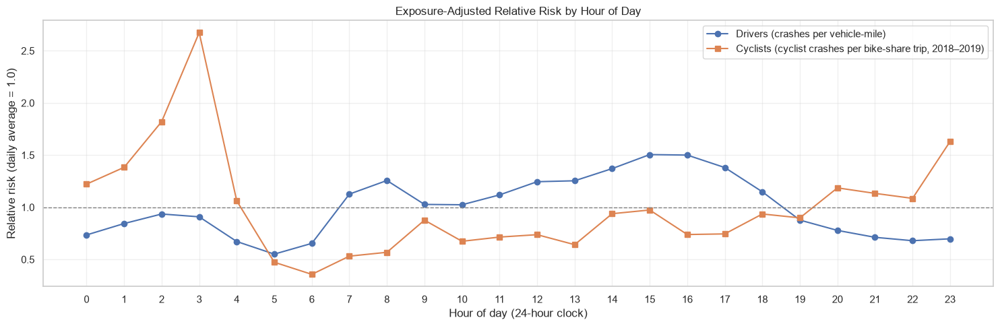

In [24]:
# Exposure-adjusted risk by weekday and hour.
# 1. Share of weekly vehicle travel in each weekday/hour cell, from ride-hail trip-miles
#    (each sample year normalised to 1, then averaged so both years count equally).
year_profile = tnp.groupby(["year", "day_index", "hour"])["trip_miles"].sum()
year_profile = year_profile / year_profile.groupby(level="year").transform("sum")
hour_share = year_profile.groupby(level=["day_index", "hour"]).mean()
hour_share = hour_share / hour_share.sum()
share_grid = hour_share.unstack("hour").reindex(index=range(7), columns=range(24), fill_value=0)
share_grid.index = days_order

# 2. Exposure in each cell = total study VMT × that cell's share of travel.
total_study_vmt = road["study_vmt"].sum()
vmt_grid = share_grid * total_study_vmt

# 3. Convert crashes per vehicle-mile into the chance that a 10-mile drive involves a reported crash,
#    using the average number of vehicles (drivers) per crash.
VEHICLES_PER_CRASH = crash_enriched["drivers"].fillna(0).clip(lower=1).mean()
TRIP_MILES = 10


def drive_probability(crashes, vmt, miles=TRIP_MILES, per=10_000):
    """Estimated crash involvements per `per` drives of `miles` miles."""
    involvement_per_mile = crashes * VEHICLES_PER_CRASH / vmt.where(vmt > 0)
    return (1 - np.exp(-involvement_per_mile * miles)) * per


rate_grid = crash_counts / (vmt_grid.where(vmt_grid > 0) / 1e6)  # crashes per million VMT
prob_grid = drive_probability(crash_counts, vmt_grid)              # per 10,000 ten-mile drives
overall_prob = drive_probability(crash_counts.to_numpy().sum(), pd.Series([total_study_vmt])).iloc[0]

# 4. Heatmaps: estimated share of travel (top) and per-drive risk (bottom).
fig, axes = plt.subplots(2, 1, figsize=(15, 11))
sns.heatmap(share_grid * 100, cmap="Blues", linewidths=0.2, ax=axes[0],
            cbar_kws={"label": "Share of weekly vehicle travel (%)"})
axes[0].set(title="Exposure: Estimated Share of Vehicle Travel by Weekday and Hour (ride-hail trip-miles)",
            xlabel="", ylabel="Day of week")
sns.heatmap(prob_grid, cmap="YlOrRd", linewidths=0.2, ax=axes[1],
            cbar_kws={"label": f"Crashes per 10,000 drives of {TRIP_MILES} miles"})
axes[1].set(title=f"Estimated Chance That a {TRIP_MILES}-Mile Drive Involves a Reported Crash, by Weekday and Hour "
                  f"(city average: {overall_prob:.2f} per 10,000 drives)",
            xlabel="Hour of day (24-hour clock)", ylabel="Day of week")
plt.tight_layout()
save_chart("per_drive_risk_heatmap")

# 5. Compare the busiest weekday/hour cells (counts) with the riskiest (per drive).
hourly_table = pd.DataFrame({
    "crashes": crash_counts.stack(),
    "share_of_travel_pct": (share_grid * 100).stack(),
    "crashes_per_million_vmt": rate_grid.stack(),
    "per_10k_drives": prob_grid.stack(),
})
hourly_table.index.names = ["day_of_week", "hour"]
hourly_table["count_rank"] = hourly_table["crashes"].rank(ascending=False, method="min").astype(int)
hourly_table["risk_rank"] = hourly_table["per_10k_drives"].rank(ascending=False, method="min").astype("Int64")
print("Highest exposure-adjusted risk (weekday/hour cells):")
display(hourly_table.sort_values("per_10k_drives", ascending=False).head(10).round(2))
print("Highest crash counts, with their exposure-adjusted rank:")
display(hourly_table.sort_values("crashes", ascending=False).head(10).round(2))

# 6. Relative risk by hour of day for drivers (crashes per vehicle-mile) and cyclists (cyclist-involved crashes
#    per bike-share trip, both 2018–2019), each scaled so its daily average equals 1.
cyclist_crashes = crash_enriched.loc[crash_enriched["cyclist_involved"]
                                     & crash_enriched["crash_date"].dt.year.isin([2018, 2019]), "crash_date"]
cyclist_index = (cyclist_crashes.dt.hour.value_counts() / divvy_hourly.groupby("hour")["trips"].sum()).reindex(range(24))
cyclist_index = cyclist_index / cyclist_index.mean()
driver_by_hour = drive_probability(crash_counts.sum(axis=0), vmt_grid.sum(axis=0))
driver_index = driver_by_hour / driver_by_hour.mean()

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(driver_index.index, driver_index.values, marker="o", label="Drivers (crashes per vehicle-mile)")
ax.plot(cyclist_index.index, cyclist_index.values, marker="s",
        label="Cyclists (cyclist crashes per bike-share trip, 2018–2019)")
ax.axhline(1, color="grey", linestyle="--", linewidth=1)
ax.set_xticks(range(24))
ax.set(xlabel="Hour of day (24-hour clock)", ylabel="Relative risk (daily average = 1.0)",
       title="Exposure-Adjusted Relative Risk by Hour of Day")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
save_chart("relative_risk_by_hour")

**Interpretation:**

- City average: about **1.89 reported-crash involvements per 10,000 drives of 10 miles** (1.71 vehicles per crash).
- Highest exposure-adjusted risk: Tuesday 16:00 (3.22 per 10,000 drives, count rank 6); Tuesday 15:00 (3.15 per 10,000 drives, count rank 7); Tuesday 17:00 (3.08 per 10,000 drives, count rank 8); Friday 15:00 (3.08 per 10,000 drives, count rank 1); Monday 16:00 (3.07 per 10,000 drives, count rank 14).
- Highest crash counts: Friday 15:00 (risk rank 4); Friday 16:00 (risk rank 7); Friday 17:00 (risk rank 19); Thursday 16:00 (risk rank 9); Thursday 15:00 (risk rank 10).
- Lowest exposure-adjusted risk: Tuesday 04:00 (0.73); Monday 05:00 (0.76); Tuesday 03:00 (0.77).
- Riskiest hour of day for drivers: **15:00** (1.50x the daily average); for cyclists: **03:00** (2.67x).
- **8 of the 10 highest-count** weekday/hour cells are also among the 10 highest-risk cells, and the rank correlation between crash counts and per-drive risk across all 168 cells is **0.87**. The busiest hours are also, to a large degree, the riskiest hours per trip: the weekday afternoon peak has both the most crashes and the highest risk per drive. Per drive, weekend early-morning hours (Sat–Sun, midnight–4 a.m.) average **1.92** per 10,000 drives versus **2.93** for weekday 3–6 p.m., so the high weekend late-night counts in Section 3.1 mostly reflect how much travel happens then.
- **Caution:** exposure by hour is estimated from ride-hail trip-miles, which over-represent evening and weekend travel. Late-night risk is therefore more likely to be understated than overstated, and the hour-by-hour values are estimates, not measured rates. Cyclist risk uses bike-share trips (2018–2019) as the exposure indicator; only those two years are used because they are the only years of Divvy trip data on the City portal that overlap the crash data.

## 4. Where do crashes occur?

This section assigns geocoded crash points to Chicago's official community-area boundaries. The boundaries were loaded and standardized in Notebook 1. The spatial join uses `within`; points exactly on a polygon boundary may remain unassigned, so unassigned records are reported explicitly.

In [25]:
# Assign each geocoded crash to the community area that contains it.
crash_points = gpd.GeoDataFrame(
    df_geo[["crash_record_id", "crash_date", "latitude", "longitude", "injuries_total", "injuries_fatal",
            "first_crash_type"]],
    geometry=gpd.points_from_xy(df_geo["longitude"], df_geo["latitude"]), crs="EPSG:4326")
crash_area = gpd.sjoin(crash_points, community_areas[["community_number", "community_name", "geometry"]],
                       how="left", predicate="within")

areas_per_crash = crash_area.dropna(subset=["community_name"]).groupby("crash_record_id")["community_name"].nunique()
print(f"Geocoded crash records: {len(crash_points):,}")
print(f"Records assigned to a community area: {crash_area['community_name'].notna().sum():,}")
print(f"Records not assigned to a community area: {crash_area['community_name'].isna().sum():,}")
print(f"Crash IDs assigned to multiple community areas: {int(areas_per_crash.gt(1).sum()):,}")

Geocoded crash records: 870,789
Records assigned to a community area: 870,427
Records not assigned to a community area: 362
Crash IDs assigned to multiple community areas: 0


### 4.1 Match crashes to streets and intersections; total exposure by community area

Each geocoded crash is matched to the nearest street block within 25 m. It is counted at an **intersection** (a network node where two or more differently named streets meet) if it lies within 30 m of the intersection, or within 75 m when the police report marks the crash as intersection-related. Crashes more than 25 m from any modelled street, such as those on expressways, in parking lots, or with imprecise coordinates, are kept in the count-based analyses but excluded from exposure-adjusted rates. This keeps each rate's numerator and denominator consistent.

Exposure is then added up by community area: VMT from each street block (assigned to the area containing its midpoint), transit boardings and bike-share trips (by station or stop location), and sampled ride-hail pickups.

In [26]:
# Match crashes to street blocks and intersections, then total the exposure measures by community area.
SNAP_DISTANCE_M = 25                # a crash is matched to a street block within 25 m of its reported location
INTERSECTION_RADIUS_M = 30          # crashes within 30 m of an intersection are counted at that intersection,
INTERSECTION_RELATED_RADIUS_M = 75  # or within 75 m if the police report marks the crash as intersection-related

# 1. Intersections: network nodes where two or more differently named streets meet. Each node's location is the
#    median of its block ends; entering volume is half the summed volume of its legs (each vehicle uses two legs).
ends = pd.concat([
    pd.DataFrame({"node_id": road[node_col], "street": road["street_full"], "adt": road["adt"],
                  "measured": road["volume_measured"], "x": end_points.x, "y": end_points.y})
    for node_col, end_points in [("fnode_id", road.geometry.interpolate(0, normalized=True)),
                                 ("tnode_id", road.geometry.interpolate(1, normalized=True))]
], ignore_index=True).dropna(subset=["node_id"])
nodes = ends.groupby("node_id").agg(
    x=("x", "median"), y=("y", "median"),
    streets=("street", lambda s: sorted(set(v for v in s if v))),
    entering_adt=("adt", lambda s: s.sum() / 2),
    measured_legs=("measured", "sum"),
)
nodes = nodes.loc[nodes["streets"].str.len() >= 2].reset_index()
nodes["intersection_name"] = nodes["streets"].apply(lambda s: " & ".join(s[:3]))
nodes = gpd.GeoDataFrame(nodes, geometry=gpd.points_from_xy(nodes["x"], nodes["y"]), crs=PROJECTED_CRS)

# 2. Nearest block and nearest intersection for every crash (saved after the first run because it is slow).
MATCH_FILE = PROCESSED_DIR / "crash_road_matches.csv"
crash_xy = (crash_area.drop_duplicates("crash_record_id")
            .merge(crash_enriched[["crash_record_id", "intersection_related_i"]], on="crash_record_id", how="left")
            [["crash_record_id", "intersection_related_i", "geometry"]].to_crs(PROJECTED_CRS))
if MATCH_FILE.exists():
    print(f"Loading saved crash-to-road matches: {MATCH_FILE}")
    road_match = pd.read_csv(MATCH_FILE, dtype={"crash_record_id": "string"})
else:
    print("Matching crashes to street blocks and intersections...")
    seg_match = (gpd.sjoin_nearest(crash_xy, road[["segment_id", "geometry"]], how="left",
                                   max_distance=SNAP_DISTANCE_M, distance_col="segment_distance_m")
                 .sort_values("segment_distance_m").drop_duplicates("crash_record_id"))
    node_match = (gpd.sjoin_nearest(crash_xy, nodes[["node_id", "geometry"]], how="left",
                                    max_distance=INTERSECTION_RELATED_RADIUS_M, distance_col="node_distance_m")
                  .sort_values("node_distance_m").drop_duplicates("crash_record_id"))
    road_match = seg_match[["crash_record_id", "segment_id", "segment_distance_m"]].merge(
        node_match[["crash_record_id", "intersection_related_i", "node_id", "node_distance_m"]],
        on="crash_record_id", how="left")
    road_match.to_csv(MATCH_FILE, index=False)

# 3. Classify each crash as at an intersection, between intersections, or not on a modelled street.
flagged_related = road_match["intersection_related_i"].astype("string").str.upper().eq("Y").fillna(False)
at_intersection = (road_match["node_distance_m"].le(INTERSECTION_RADIUS_M)
                   | (road_match["node_distance_m"].le(INTERSECTION_RELATED_RADIUS_M) & flagged_related)
                   ).fillna(False).astype(bool)
road_match["node_id"] = road_match["node_id"].where(at_intersection)
road_match["location_type"] = np.select([at_intersection, road_match["segment_id"].notna()],
                                        ["Intersection", "Between intersections"], "Not on a modelled street")

# 4. One analysis table: crash attributes, community area, road match and outcomes.
crash_road = (crash_area.drop_duplicates("crash_record_id").drop(columns="geometry")
              .merge(road_match[["crash_record_id", "segment_id", "node_id", "location_type"]],
                     on="crash_record_id", how="left")
              .merge(crash_enriched[["crash_record_id", "serious_outcome", "pedestrian_involved", "cyclist_involved"]],
                     on="crash_record_id", how="left"))
crash_road["serious_crash"] = crash_road["serious_outcome"].fillna(False).astype(bool)
crash_road["fatal_crash"] = crash_road["injuries_fatal"].fillna(0).gt(0)
crash_road["on_modelled_street"] = crash_road["segment_id"].notna()
display(crash_road["location_type"].value_counts().rename("crashes").to_frame()
        .assign(pct=lambda t: (t["crashes"] / t["crashes"].sum() * 100).round(1)))

# 5. Exposure by community area: VMT from the blocks whose midpoint lies in the area, plus transit boardings,
#    bike-share trips and sampled ride-hail pickups located in the area.
areas_projected = community_areas[["community_number", "community_name", "geometry"]].to_crs(PROJECTED_CRS)
road["community_name"] = road["segment_id"].map(
    gpd.sjoin(midpoints[["segment_id", "geometry"]], areas_projected, how="left", predicate="within")
    .drop_duplicates("segment_id").set_index("segment_id")["community_name"])


def points_to_areas(frame, value_col):
    """Sum a value (boardings, trips) by community area using each point's lat/lon."""
    pts = frame.dropna(subset=["lat", "lon", value_col])
    pts = gpd.GeoDataFrame(pts[[value_col]], geometry=gpd.points_from_xy(pts["lon"], pts["lat"]), crs="EPSG:4326")
    return (gpd.sjoin(pts, community_areas[["community_name", "geometry"]], how="inner", predicate="within")
            .groupby("community_name")[value_col].sum())


by_area = road.groupby("community_name")
area_exposure = pd.DataFrame({
    "street_miles": by_area["length_mi"].sum(),
    "daily_vmt": by_area["daily_vmt"].sum(),
    "study_vmt": by_area["study_vmt"].sum(),
    "measured_vmt_share_pct": road.loc[road["volume_measured"]].groupby("community_name")["daily_vmt"].sum()
                              / by_area["daily_vmt"].sum() * 100,
    "l_daily_entries": points_to_areas(l_stations, "avg_daily_entries"),
    "bus_weekday_boardings": points_to_areas(bus_stops, "boardings"),
    "divvy_trips_2018_2019": points_to_areas(divvy_stations, "trips"),
})
area_numbers = community_areas.set_index("community_number")["community_name"].to_dict()
area_exposure["ridehail_sample_pickups"] = (tnp.groupby("pickup_community_area")["trips"].sum()
                                            .rename(index=area_numbers).reindex(area_exposure.index))
area_exposure = area_exposure.fillna({"measured_vmt_share_pct": 0, "l_daily_entries": 0,
                                      "bus_weekday_boardings": 0, "divvy_trips_2018_2019": 0})
area_exposure["transit_daily_boardings"] = area_exposure["l_daily_entries"] + area_exposure["bus_weekday_boardings"]
area_exposure.index.name = "community_name"

print(f"Crashes matched to a modelled street: {crash_road['on_modelled_street'].mean() * 100:.1f}%")
print(f"Crashes counted at an intersection: {crash_road['location_type'].eq('Intersection').mean() * 100:.1f}%")
print(f"Intersections in the network: {len(nodes):,}")

Loading saved crash-to-road matches: /Users/armon/data/processed/crash_road_matches.csv


,crashes,pct
location_type,,
Intersection,544914,62.6
Between intersections,325267,37.4
Not on a modelled street,608,0.1


Crashes matched to a modelled street: 99.9%
Crashes counted at an intersection: 62.6%
Intersections in the network: 25,359


### 4.2 Street corridors and intersections

Street blocks are grouped into **half-mile corridor sections**: the same street within a 400-number address band. Chicago's grid has 800 address numbers per mile. For each corridor and intersection, the notebook counts crashes and calculates standard exposure-adjusted rates:

- **Corridors:** crashes per million vehicle-miles travelled.
- **Intersections:** crashes per million entering vehicles (MEV). Entering vehicles = half the summed daily volume of the intersection's legs × days.

A rate is ranked only when it rests on **at least 30 crashes** and mostly measured traffic: for corridors, at least 5 million vehicle-miles; for intersections, measured volume on at least two legs. With fewer crashes, one or two extra crashes move a rate a great deal. In an earlier version with a 10-crash minimum, a quiet residential intersection with 14 crashes and about 500 vehicles a day ranked third, which said more about its small traffic volume than about its safety.

**Robustness check: the busier-road rule.** The first run of the rate rankings was dominated by quiet streets alongside Lake Shore Drive and at expressway interchanges. Crashes on the busy road are often recorded at these nearby quieter locations, so their crashes were being divided by the quiet street's small traffic volume. After spotting this, I added a rule: a location within 60 m of a road carrying at least 2.5 times its own traffic (and at least 20,000 vehicles a day) is left out of the rate rankings. These locations stay in the count lists. Because the rule was added after looking at the results, the rate rankings for individual locations should be read as a screening list for engineering review rather than final estimates.

In [27]:
# Crash totals and exposure-adjusted rates for half-mile street corridors and for intersections.
CORRIDOR_ADDRESS_SPAN = 400  # Chicago's grid has 800 address numbers per mile, so 400 = a half-mile section
MIN_CORRIDOR_VMT = 5e6       # minimum vehicle-miles over the study period before a corridor rate is ranked
MIN_RATE_CRASHES = 30        # minimum crashes before a rate is ranked (small counts give unstable rates)
BUSY_ROAD_RADIUS_M = 60      # locations within 60 m of a much busier road are left out of rate rankings,
BUSY_ROAD_RATIO = 2.5        # where "much busier" means at least 2.5 times the location's own volume
BUSY_ROAD_MIN_ADT = 20000    # and at least 20,000 vehicles a day


def street_title(name):
    """Readable street and place names: '95Th' -> '95th', 'Lsd' -> 'LSD', 'Ohare' -> "O'Hare"."""
    if not isinstance(name, str) or not name:
        return ""
    text = re.sub(r"(\d+)(St|Nd|Rd|Th)\b", lambda m: m.group(1) + m.group(2).lower(), name.title())
    return text.replace("Lsd", "LSD").replace("Ohare", "O'Hare")


# 1. Busy roads (at least 20,000 vehicles a day) from the street model and from IDOT counts, which include
#    expressways. Crashes on a busy road are sometimes recorded on a quieter street beside it (for example Lake
#    Shore Drive crashes placed on adjacent local streets), so those quieter locations are excluded from rate
#    rankings to avoid dividing the busy road's crashes by the quiet street's small volume.
busy_roads = gpd.GeoDataFrame(pd.concat([
    road.loc[road["volume_measured"] & road["adt"].ge(BUSY_ROAD_MIN_ADT), ["adt", "geometry"]],
    idot_aadt.loc[idot_aadt["AADT"].ge(BUSY_ROAD_MIN_ADT), ["AADT", "geometry"]]
             .rename(columns={"AADT": "adt"}).to_crs(PROJECTED_CRS),
], ignore_index=True), geometry="geometry", crs=PROJECTED_CRS)
busy_roads["geometry"] = busy_roads.geometry.buffer(BUSY_ROAD_RADIUS_M)


def max_nearby_volume(points):
    """Largest daily volume of any busy road within BUSY_ROAD_RADIUS_M of each point (0 if none)."""
    hits = gpd.sjoin(points, busy_roads, how="inner", predicate="within")
    return hits.groupby(level=0)["adt"].max().reindex(points.index, fill_value=0)


def crash_totals(key):
    """Crash, serious, fatal and pedestrian counts per block (segment_id) or intersection (node_id)."""
    return crash_road.dropna(subset=[key]).groupby(key).agg(
        crashes=("crash_record_id", "nunique"), serious_crashes=("serious_crash", "sum"),
        fatal_crashes=("fatal_crash", "sum"), pedestrian_crashes=("pedestrian_involved", "sum"))


crash_outcomes = ["crashes", "serious_crashes", "fatal_crashes", "pedestrian_crashes"]

# 2. Corridor sections: blocks on the same street within the same half-mile address band
#    (blocks without addresses stay on their own).
band_start = (road[["l_f_add", "l_t_add", "r_f_add", "r_t_add"]].where(lambda t: t > 0).min(axis=1)
              // CORRIDOR_ADDRESS_SPAN * CORRIDOR_ADDRESS_SPAN)
has_band = band_start.notna()
band = band_start.fillna(0).astype(int)
road["corridor_id"] = np.where(has_band, road["street_full"] + " | " + band.astype(str),
                               road["street_full"] + " | block " + road["segment_id"].astype(str))
road["corridor_name"] = np.where(has_band,
                                 band.astype(str) + "–" + (band + CORRIDOR_ADDRESS_SPAN - 1).astype(str) + " "
                                 + road["street_full"], road["street_full"] + " (unaddressed block)")

# 3. Add each block's crash counts, midpoint (for mapping) and nearby busy-road volume.
road = road.drop(columns=crash_outcomes, errors="ignore").join(crash_totals("segment_id"), on="segment_id")
road[crash_outcomes] = road[crash_outcomes].fillna(0)
mid_projected = road.geometry.interpolate(0.5, normalized=True)
mid_lonlat = mid_projected.to_crs("EPSG:4326")
road["mid_lon"], road["mid_lat"] = mid_lonlat.x, mid_lonlat.y
road["measured_vmt"] = road["study_vmt"].where(road["volume_measured"], 0)
road["nearby_busy_adt"] = max_nearby_volume(gpd.GeoDataFrame(road[["segment_id"]], geometry=mid_projected,
                                                               crs=PROJECTED_CRS))

# 4. Corridor totals and rates (crashes per million VMT; serious crashes per 100 million VMT).
corridors = road.groupby("corridor_id").agg(
    corridor_name=("corridor_name", "first"),
    community_name=("community_name", lambda s: s.mode().iat[0] if s.notna().any() else pd.NA),
    road_class=("road_class", lambda s: s.mode().iat[0]),
    length_mi=("length_mi", "sum"), study_vmt=("study_vmt", "sum"), measured_vmt=("measured_vmt", "sum"),
    lat=("mid_lat", "mean"), lon=("mid_lon", "mean"), nearby_busy_adt=("nearby_busy_adt", "max"),
    **{c: (c, "sum") for c in crash_outcomes},
).reset_index()
corridors["avg_daily_volume"] = corridors["study_vmt"] / STUDY_DAYS / corridors["length_mi"]
corridors["measured_vmt_share_pct"] = corridors["measured_vmt"] / corridors["study_vmt"] * 100
corridors["crashes_per_million_vmt"] = corridors["crashes"] / (corridors["study_vmt"] / 1e6)
corridors["serious_per_100m_vmt"] = corridors["serious_crashes"] / (corridors["study_vmt"] / 1e8)
corridors["near_much_busier_road"] = (corridors["nearby_busy_adt"]
                                      >= BUSY_ROAD_RATIO * corridors["avg_daily_volume"].clip(lower=1))
corridors["rate_reliable"] = (corridors["measured_vmt_share_pct"].ge(50) & corridors["study_vmt"].ge(MIN_CORRIDOR_VMT)
                              & corridors["crashes"].ge(MIN_RATE_CRASHES) & ~corridors["near_much_busier_road"])

# 5. Intersection totals and rates (crashes per million entering vehicles, MEV). Intersections on a
#    community-area boundary take the nearest area.
intersections = nodes.drop(columns="geometry").join(crash_totals("node_id"), on="node_id")
intersections[crash_outcomes] = intersections[crash_outcomes].fillna(0)
node_lonlat = nodes.geometry.to_crs("EPSG:4326")
intersections["lon"], intersections["lat"] = node_lonlat.x.to_numpy(), node_lonlat.y.to_numpy()
entering_vehicles = intersections["entering_adt"] * STUDY_DAYS
intersections["crashes_per_mev"] = intersections["crashes"] / (entering_vehicles / 1e6)
intersections["serious_per_100mev"] = intersections["serious_crashes"] / (entering_vehicles / 1e8)
intersections["near_much_busier_road"] = (max_nearby_volume(nodes[["geometry"]]).to_numpy()
                                          >= BUSY_ROAD_RATIO * intersections["entering_adt"].clip(lower=1))
intersections["rate_reliable"] = (intersections["measured_legs"].ge(2) & intersections["crashes"].ge(MIN_RATE_CRASHES)
                                  & ~intersections["near_much_busier_road"])
intersections["community_name"] = intersections["node_id"].map(
    gpd.sjoin_nearest(nodes[["node_id", "geometry"]], areas_projected, how="left", max_distance=100)
    .drop_duplicates("node_id").set_index("node_id")["community_name"])

print(f"Corridor sections: {len(corridors):,} ({corridors['rate_reliable'].sum():,} with a reliable rate; "
      f"{corridors['near_much_busier_road'].sum():,} excluded from rate rankings as next to a much busier road)")
print(f"Intersections with at least one crash: {intersections['crashes'].gt(0).sum():,} "
      f"({intersections['rate_reliable'].sum():,} with a reliable rate; "
      f"{intersections['near_much_busier_road'].sum():,} excluded from rate rankings as next to a much busier road)")

Corridor sections: 11,538 (1,580 with a reliable rate; 1,758 excluded from rate rankings as next to a much busier road)
Intersections with at least one crash: 23,301 (4,547 with a reliable rate; 679 excluded from rate rankings as next to a much busier road)


### 4.3 Interactive crash-density and exposure-adjusted risk map

The interactive map uses **every** valid crash location, aggregated to a grid of roughly 150-metre cells so the figure stays light enough to render. Use the dropdown menu to switch between:

- **Count views:** all reported crashes, injury crashes, serious-outcome crashes, the weekday afternoon peak (Monday–Friday, 3–6 p.m.), and late night (midnight–5 a.m.).
- **Exposure-adjusted views:** half-mile corridors coloured by crashes per million vehicle-miles, and intersections coloured by crashes per million entering vehicles. Point size reflects the number of crashes.

Community-area boundaries are overlaid. Hover over an area to see its 2018–2025 totals, serious-outcome share, exposure-adjusted rate and ranks. Individual fatal-crash locations can be toggled in the legend. Outlines highlight the 10 areas with the most crashes, the highest serious-outcome share, or (in the exposure-adjusted views) the highest crash rate per vehicle-mile.

The heat colours are scaled within each view so the busiest ~1% of the map reaches the top colour, so colours are relative and not comparable across views. In the exposure-adjusted views, colours are capped at the 95th percentile so a few extreme values do not wash out the rest.

Crashes mapped: 870,789 (all valid geocoded crashes; no sampling)
Fatal crash locations shown: 972
Corridors shown in the exposure-adjusted view: 1,580; intersections: 4,547


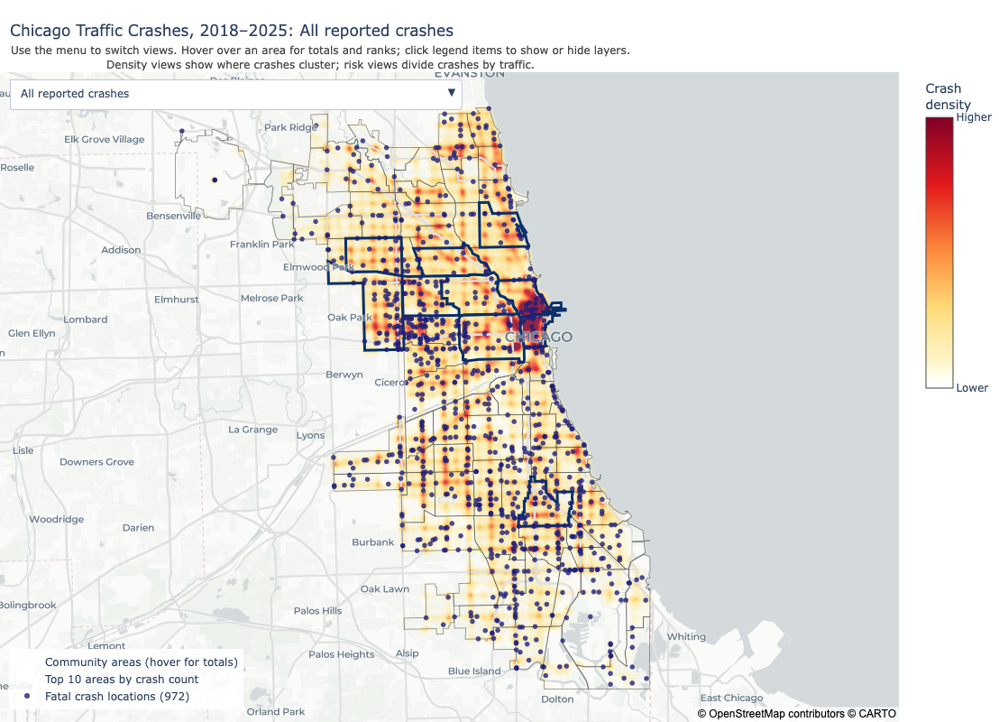

In [28]:
# Interactive crash map built from ALL valid crash locations, with count views and exposure-adjusted risk views.
# Crashes are aggregated to a ~150 m grid, which keeps the figure light while using every geocoded record.
MAP_CENTER = {"lat": 41.835, "lon": -87.70}
MAP_ZOOM = 9.8
GRID_DEG = 0.0015  # grid cell size in degrees (~150 m north-south)

# 1. One row per geocoded crash, with the flags used by the map views (crash_road already holds them).
map_points = crash_road.assign(hour=crash_road["crash_date"].dt.hour,
                               weekday=crash_road["crash_date"].dt.dayofweek,  # Monday = 0
                               injury_crash=crash_road["injuries_total"].fillna(0).gt(0))

# 2. Each count view is a filter on the same set of crashes.
map_views = {
    "All reported crashes": pd.Series(True, index=map_points.index),
    "Injury crashes": map_points["injury_crash"],
    "Serious-outcome crashes (fatal or incapacitating)": map_points["serious_crash"],
    "Weekday afternoon peak (Mon–Fri, 3–6 p.m.)": map_points["weekday"].lt(5) & map_points["hour"].between(15, 17),
    "Late night (midnight–5 a.m., all days)": map_points["hour"].between(0, 4),
}
SERIOUS_VIEW = 2


# 3. Helpers: bin crashes to the grid, and set each heat layer's colour scale so the busiest ~1% of the map
#    reaches the top colour (otherwise the whole city saturates).
def bin_to_grid(points, step=GRID_DEG):
    """Count crashes in each grid cell."""
    cells = pd.DataFrame({
        "lat": (points["latitude"] / step).round() * step,
        "lon": (points["longitude"] / step).round() * step,
    })
    return cells.value_counts().rename("crashes").reset_index()


def estimate_color_max(cells, radius_px, zoom=MAP_ZOOM, quantile=0.99):
    """Approximate the rendered heat-map density at the starting zoom so the colour scale
    tops out at the busiest ~1% of the map instead of saturating the whole city."""
    px_per_deg = 512 * 2 ** zoom / 360  # MapLibre uses 512-px tiles
    x = cells["lon"].to_numpy() * px_per_deg
    y = np.degrees(np.log(np.tan(np.pi / 4 + np.radians(cells["lat"].to_numpy()) / 2))) * px_per_deg
    xi = np.round(x - x.min()).astype(int) + radius_px
    yi = np.round(y - y.min()).astype(int) + radius_px
    grid = np.zeros((yi.max() + radius_px + 1, xi.max() + radius_px + 1))
    np.add.at(grid, (yi, xi), cells["crashes"].to_numpy(dtype=float))
    density = np.zeros_like(grid)
    for dy in range(-radius_px, radius_px + 1):
        for dx in range(-radius_px, radius_px + 1):
            dist2 = (dx ** 2 + dy ** 2) / radius_px ** 2
            if dist2 <= 1:  # same Gaussian kernel MapLibre uses for heat maps
                density += 0.3989 * np.exp(-4.5 * dist2) * np.roll(grid, (dy, dx), axis=(0, 1))
    lit = density[density > 0.02]
    return float(np.quantile(lit, quantile)) if lit.size else 1.0


# 4. Community-area totals and ranks for the hover labels and highlight outlines.
area_stats = map_points.dropna(subset=["community_name"]).groupby("community_name").agg(
    total_crashes=("crash_record_id", "nunique"), injury_crashes=("injury_crash", "sum"),
    known_outcomes=("serious_outcome", "count"), serious_crashes=("serious_crash", "sum"),
    fatal_crashes=("fatal_crash", "sum"),
).reset_index()
area_stats["serious_share_pct"] = (
    area_stats["serious_crashes"] / area_stats["known_outcomes"].replace(0, np.nan) * 100
).fillna(0)
area_stats["count_rank"] = area_stats["total_crashes"].rank(method="min", ascending=False).astype(int)
area_stats["share_rank"] = area_stats["serious_share_pct"].rank(method="min", ascending=False).astype(int)
# Exposure-adjusted rate: crashes on modelled streets per million vehicle-miles travelled in the area.
area_rate = (crash_road.loc[crash_road["on_modelled_street"]].groupby("community_name").size()
             / (area_exposure["study_vmt"] / 1e6)).dropna()
area_stats["crashes_per_million_vmt"] = area_stats["community_name"].map(area_rate).fillna(0)
area_stats["vmt_rank"] = area_stats["crashes_per_million_vmt"].rank(method="min", ascending=False).astype(int)
n_areas = len(area_stats)

# 5. Simplified boundary shapes shared by all maps in the notebook, and a transparent fill for outline layers.
boundaries = community_areas[["community_name", "geometry"]].copy()
boundaries["community_name"] = boundaries["community_name"].astype(str)
boundaries["geometry"] = boundaries.geometry.simplify(0.0001)
boundary_geojson = boundaries.__geo_interface__
clear_fill = [[0, "rgba(0,0,0,0)"], [1, "rgba(0,0,0,0)"]]

heat_scale = [
    [0.00, "rgba(255,255,204,0)"],
    [0.10, "rgba(255,237,160,0.6)"],
    [0.30, "#fed976"],
    [0.50, "#fd8d3c"],
    [0.75, "#e31a1c"],
    [1.00, "#800026"],
]

# 6. Build the map layers.
fig = go.Figure()
view_names = list(map_views)

# Traces 0–4: one heat layer per view (only the first is visible at start).
for i, (view, mask) in enumerate(map_views.items()):
    cells = bin_to_grid(map_points.loc[mask])
    radius = 7 if mask.sum() > 100_000 else 10
    zmax = estimate_color_max(cells, radius)
    fig.add_trace(go.Densitymap(
        lat=cells["lat"], lon=cells["lon"], z=cells["crashes"],
        radius=radius, zmin=0, zmax=zmax, colorscale=heat_scale, opacity=0.85,
        hoverinfo="skip", name=view, showlegend=False, visible=(i == 0),
        colorbar=dict(title=dict(text="Crash<br>density"), tickvals=[0, zmax],
                      ticktext=["Lower", "Higher"], len=0.5, y=0.75)
    ))

# Trace 5: community-area boundaries with hover statistics.
fig.add_trace(go.Choroplethmap(
    geojson=boundary_geojson, featureidkey="properties.community_name",
    locations=area_stats["community_name"].astype(str), z=area_stats["total_crashes"],
    colorscale=clear_fill, showscale=False,
    marker=dict(line=dict(width=0.8, color="rgba(60,60,60,0.6)")),
    customdata=np.column_stack([
        area_stats["community_name"].map(street_title),
        area_stats["total_crashes"], area_stats["count_rank"],
        area_stats["injury_crashes"], area_stats["serious_crashes"],
        area_stats["serious_share_pct"].round(2), area_stats["share_rank"],
        area_stats["fatal_crashes"],
        area_stats["crashes_per_million_vmt"].round(2), area_stats["vmt_rank"],
    ]),
    hovertemplate=(
        "<b>%{customdata[0]}</b><br>"
        f"Reported crashes: %{{customdata[1]:,}} (rank %{{customdata[2]}} of {n_areas})<br>"
        "Injury crashes: %{customdata[3]:,}<br>"
        "Serious-outcome crashes: %{customdata[4]:,}<br>"
        f"Serious-outcome share: %{{customdata[5]:.2f}}% (rank %{{customdata[6]}} of {n_areas})<br>"
        "Fatal crashes: %{customdata[7]:,}<br>"
        f"Crashes per million vehicle-miles: %{{customdata[8]:.2f}} (rank %{{customdata[9]}} of {n_areas})"
        "<extra></extra>"
    ),
    name="Community areas (hover for totals)", showlegend=True
))


def outline_trace(names, label, color, visible):
    names = list(names.astype(str))
    return go.Choroplethmap(
        geojson=boundary_geojson, featureidkey="properties.community_name",
        locations=names, z=[1] * len(names), colorscale=clear_fill, showscale=False,
        marker=dict(line=dict(width=3, color=color)), hoverinfo="skip",
        name=label, showlegend=True, visible=visible
    )


# Traces 6–7: highlight the top 10 areas by count (crash views) or by serious-outcome share (serious view).
fig.add_trace(outline_trace(area_stats.nlargest(10, "total_crashes")["community_name"],
                            "Top 10 areas by crash count", "#08306b", True))
fig.add_trace(outline_trace(area_stats.nlargest(10, "serious_share_pct")["community_name"],
                            "Top 10 areas by serious-outcome share", "#6a00a8", False))

# Trace 8: individual fatal crashes (toggle in the legend).
fatal = map_points.loc[map_points["fatal_crash"]]
fig.add_trace(go.Scattermap(
    lat=fatal["latitude"], lon=fatal["longitude"], mode="markers",
    marker=dict(size=6, color="#1f1f7a", opacity=0.8),
    customdata=np.column_stack([
        fatal["crash_date"].dt.strftime("%b %d, %Y %I:%M %p"),
        fatal["first_crash_type"].fillna("Unknown").map(street_title),
        fatal["community_name"].fillna("Unassigned").map(street_title),
        fatal["injuries_fatal"].astype(int),
    ]),
    hovertemplate=("<b>Fatal crash</b><br>%{customdata[0]}<br>%{customdata[1]}<br>"
                   "%{customdata[2]}<br>Deaths: %{customdata[3]}<extra></extra>"),
    name=f"Fatal crash locations ({len(fatal):,})"
))

# Traces 9–10: exposure-adjusted risk (crashes relative to traffic volume) for corridors and intersections.
risk_scale = "Turbo"
risk_corr = corridors.loc[corridors["rate_reliable"]].sort_values("crashes_per_million_vmt")
corr_cap = risk_corr["crashes_per_million_vmt"].quantile(0.95)
fig.add_trace(go.Scattermap(
    lat=risk_corr["lat"], lon=risk_corr["lon"], mode="markers", visible=False,
    marker=dict(size=np.clip(np.sqrt(risk_corr["crashes"]) * 0.9, 4, 16),
                color=risk_corr["crashes_per_million_vmt"], colorscale=risk_scale, cmin=0, cmax=corr_cap,
                opacity=0.85, colorbar=dict(title=dict(text="Crashes per<br>million VMT"), len=0.5, y=0.75)),
    customdata=np.column_stack([
        risk_corr["corridor_name"].map(street_title),
        risk_corr["community_name"].fillna("").map(street_title),
        risk_corr["crashes"].astype(int), risk_corr["serious_crashes"].astype(int),
        risk_corr["avg_daily_volume"].round(0), risk_corr["crashes_per_million_vmt"].round(2),
        risk_corr["serious_per_100m_vmt"].round(1),
    ]),
    hovertemplate=("<b>%{customdata[0]}</b><br>%{customdata[1]}<br>Crashes: %{customdata[2]:,} "
                   "(serious: %{customdata[3]:,})<br>Average daily traffic: %{customdata[4]:,.0f} vehicles<br>"
                   "Crashes per million vehicle-miles: %{customdata[5]:.2f}<br>"
                   "Serious crashes per 100 million vehicle-miles: %{customdata[6]:.1f}<extra></extra>"),
    name="Corridor risk (crashes per million VMT)", showlegend=False
))
risk_int = intersections.loc[intersections["rate_reliable"]].sort_values("crashes_per_mev")
int_cap = risk_int["crashes_per_mev"].quantile(0.95)
fig.add_trace(go.Scattermap(
    lat=risk_int["lat"], lon=risk_int["lon"], mode="markers", visible=False,
    marker=dict(size=np.clip(np.sqrt(risk_int["crashes"]) * 0.9, 4, 18),
                color=risk_int["crashes_per_mev"], colorscale=risk_scale, cmin=0, cmax=int_cap,
                opacity=0.85, colorbar=dict(title=dict(text="Crashes per million<br>entering vehicles"), len=0.5, y=0.75)),
    customdata=np.column_stack([
        risk_int["intersection_name"].map(street_title),
        risk_int["community_name"].fillna("").map(street_title),
        risk_int["crashes"].astype(int), risk_int["serious_crashes"].astype(int),
        risk_int["entering_adt"].round(0), risk_int["crashes_per_mev"].round(2),
    ]),
    hovertemplate=("<b>%{customdata[0]}</b><br>%{customdata[1]}<br>Crashes: %{customdata[2]:,} "
                   "(serious: %{customdata[3]:,})<br>Vehicles entering per day: %{customdata[4]:,.0f}<br>"
                   "Crashes per million entering vehicles: %{customdata[5]:.2f}<extra></extra>"),
    name="Intersection risk (crashes per million entering vehicles)", showlegend=False
))

# Trace 11: outline the 10 areas with the highest crashes per million VMT (shown in the risk views).
fig.add_trace(outline_trace(area_rate.nlargest(10).index.to_series(),
                            "Top 10 areas by crashes per million VMT", "#000000", False))

# 7. Dropdown menu: switch view; the exposure-adjusted views swap the heat layer for rate-coloured points.
risk_views = ["Exposure-adjusted risk: street corridors (crashes per million vehicle-miles)",
              "Exposure-adjusted risk: intersections (crashes per million entering vehicles)"]
all_views = view_names + risk_views
toggle_traces = list(range(len(view_names))) + [6, 7, 9, 10, 11]
buttons = []
for i, view in enumerate(all_views):
    is_risk = i >= len(view_names)
    visible = ([j == i for j in range(len(view_names))]
               + [not is_risk and i != SERIOUS_VIEW, i == SERIOUS_VIEW,
                  i == len(view_names), i == len(view_names) + 1, is_risk])
    buttons.append(dict(
        label=view, method="update",
        args=[{"visible": visible},
              {"title.text": f"Chicago Traffic Crashes, 2018–2025: {view}"},
              toggle_traces]
    ))

fig.update_layout(
    title=dict(text=f"Chicago Traffic Crashes, 2018–2025: {view_names[0]}", x=0.01),
    map=dict(style="carto-positron", center=MAP_CENTER, zoom=MAP_ZOOM),
    height=800, margin=dict(r=0, t=80, l=0, b=0),
    updatemenus=[dict(buttons=buttons, direction="down", showactive=True,
                      x=0.01, xanchor="left", y=0.99, yanchor="top", bgcolor="white")],
    legend=dict(x=0.01, xanchor="left", y=0.02, yanchor="bottom", bgcolor="rgba(255,255,255,0.85)"),
    annotations=[dict(
        text=("Use the menu to switch views. Hover over an area for totals and ranks; click legend items to "
              "show or hide layers.<br>Density views show where crashes cluster; risk views divide crashes by traffic."),
        x=0.01, y=1.0, xref="paper", yref="paper", xanchor="left", yanchor="bottom",
        showarrow=False, font=dict(size=12, color="#444")
    )]
)

print(f"Crashes mapped: {len(map_points):,} (all valid geocoded crashes; no sampling)")
print(f"Fatal crash locations shown: {len(fatal):,}")
print(f"Corridors shown in the exposure-adjusted view: {len(risk_corr):,}; intersections: {len(risk_int):,}")
save_map(fig, "crash_density_and_risk", "Chicago crash density and exposure-adjusted risk")

### 4.4 Community-area crash counts

Count unique crash IDs in each community area and map those counts. Counts identify areas with the largest number of reported crashes, but larger or busier areas may naturally have more crashes. Hover over an area to see its name, count and rank.

,community_number,community_name,total_crashes,crash_rank
24,25.0,AUSTIN,41419,1
27,28.0,NEAR WEST SIDE,40480,2
7,8.0,NEAR NORTH SIDE,38885,3
31,32.0,LOOP,28338,4
23,24.0,WEST TOWN,25594,5
18,19.0,BELMONT CRAGIN,22260,6
21,22.0,LOGAN SQUARE,20435,7
22,23.0,HUMBOLDT PARK,19739,8
5,6.0,LAKE VIEW,19697,9
68,69.0,GREATER GRAND CROSSING,18449,10


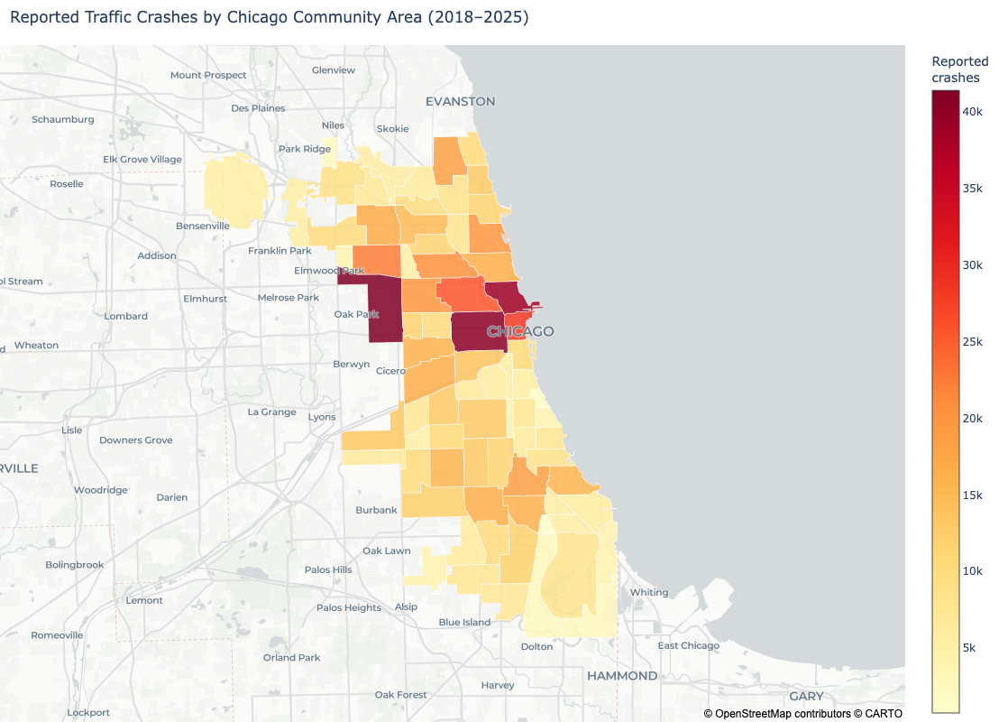

In [29]:
# Count crashes by community area (one spatial assignment per crash ID) and map them interactively.
crash_area_unique = crash_area.sort_values("crash_date").drop_duplicates(subset=["crash_record_id"])
area_summary = (crash_area_unique.dropna(subset=["community_name"])
                .groupby(["community_number", "community_name"])
                .agg(total_crashes=("crash_record_id", "nunique")).reset_index())
area_summary["crash_rank"] = area_summary["total_crashes"].rank(method="min", ascending=False).astype(int)
display(area_summary.sort_values("total_crashes", ascending=False).head(15))

crash_map = community_areas.merge(area_summary, on=["community_number", "community_name"], how="left", validate="one_to_one")


def area_choropleth(map_frame, value_col, title, colorscale, value_label, value_format=",.0f", extra=None):
    """Interactive community-area map. Hovering over an area shows its name and values.

    extra: optional {column: (label, d3 number format)} for additional hover lines.
    """
    frame = map_frame.copy()
    frame["community_name"] = frame["community_name"].astype(str)
    extra = extra or {}
    customdata = np.column_stack(
        [frame["community_name"].map(street_title), frame[value_col]] + [frame[col] for col in extra]
    )
    hovertemplate = "<b>%{customdata[0]}</b><br>" + f"{value_label}: %{{customdata[1]:{value_format}}}"
    for k, (label, fmt) in enumerate(extra.values(), start=2):
        hovertemplate += f"<br>{label}: %{{customdata[{k}]:{fmt}}}"
    hovertemplate += "<extra></extra>"

    has_value = frame[value_col].notna()
    fig = go.Figure(go.Choroplethmap(
        geojson=boundary_geojson, featureidkey="properties.community_name",
        locations=frame.loc[has_value, "community_name"], z=frame.loc[has_value, value_col],
        customdata=customdata[has_value.to_numpy()], hovertemplate=hovertemplate,
        colorscale=colorscale, marker=dict(opacity=0.85, line=dict(width=0.6, color="white")),
        colorbar=dict(title=dict(text=value_label.replace(" ", "<br>", 1)))
    ))
    if (~has_value).any():  # areas without a value are drawn in grey, still with a name tooltip
        fig.add_trace(go.Choroplethmap(
            geojson=boundary_geojson, featureidkey="properties.community_name",
            locations=frame.loc[~has_value, "community_name"], z=[0] * int((~has_value).sum()),
            colorscale=[[0, "lightgrey"], [1, "lightgrey"]], showscale=False,
            customdata=frame.loc[~has_value, ["community_name"]].apply(lambda s: s.map(street_title)).to_numpy(),
            hovertemplate="<b>%{customdata[0]}</b><br>No data<extra></extra>",
        ))
    fig.update_layout(
        title=dict(text=title, x=0.01),
        map=dict(style="carto-positron", center={"lat": 41.835, "lon": -87.69}, zoom=9.6),
        height=800, margin=dict(r=0, t=50, l=0, b=0),
    )
    return fig


save_map(area_choropleth(
    crash_map, "total_crashes", "Reported Traffic Crashes by Chicago Community Area (2018–2025)",
    "YlOrRd", "Reported crashes", extra={"crash_rank": ("Rank (of 77)", "d")}
), "crashes_by_area", "Chicago crashes by community area")

**Interpretation:**

- **Highest counts (2018–2025):** **Austin (41,419)**, **Near West Side (40,480)** and **Near North Side (38,885)** stand well above the rest, followed by the **Loop (28,338)**, **West Town (25,594)**, **Belmont Cragin (22,260)**, **Logan Square (20,435)**, **Humboldt Park (19,739)**, **Lake View (19,697)** and **Greater Grand Crossing (18,449)**. These 10 of 77 areas account for about 275,300 crashes, roughly **32%** of all crashes assigned to a community area.
- **Comparison with the density map:** The two views agree on the downtown core. The Loop, Near North Side and Near West Side, all in the top four by count, form the most intense continuous hot spot on the density map. Away from downtown, the density map shows crashes concentrated along the city's arterial street grid rather than evenly across neighbourhoods.
- **Where the rankings differ:** Austin ranks **first** by count but does not form a single hot spot on the density map, because its crashes are spread over one of the city's largest community areas (roughly 7 square miles). The Loop ranks only fourth by count but covers about 1.6 square miles, so its crashes are among the most tightly packed in the city. Area-level counts partly reflect each area's size, population, and road network, which is why point density and area totals tell somewhat different stories.
- **Counts versus risk per mile driven (Section 6.2),** against a citywide rate of 11.19 crashes per million vehicle-miles:
  - *Still high once traffic is considered:* Near West Side (19.66, rank 2), Near North Side (16.78, rank 7) and Austin (16.76, rank 8). Their high counts are not just a result of heavy traffic.
  - *Much lower once traffic is considered:* the Loop (12.45) and West Town (12.83) fall outside the top 20, and Lake View (9.26, rank 47) and Lincoln Park (7.97, rank 58) fall further. Their high counts mainly reflect how much traffic passes through them.

## 5. Where are serious crash outcomes concentrated?

A serious-outcome crash is defined as a crash with at least one person classified as `FATAL` or `INCAPACITATING INJURY` in the People dataset.

Two measures answer different questions:
- **Serious-outcome count:** how many crashes involved at least one serious outcome?
- **Serious-outcome share:** what percentage of crashes with known person-level outcomes were serious?

The table below lists the areas with the most serious-outcome crashes, and the map shows the share. The denominator excludes crashes with unknown outcome status. A community area can have a high percentage but a comparatively small number of serious crashes.

In [30]:
# Serious-outcome counts and shares by community area (share = serious / crashes with a known outcome).
serious_area_summary = (
    crash_area_unique.merge(crash_enriched[["crash_record_id", "serious_outcome"]], on="crash_record_id",
                            how="left", validate="one_to_one")
    .dropna(subset=["community_name"])
    .groupby(["community_number", "community_name"])
    .agg(total_crashes=("crash_record_id", "nunique"),
         crashes_with_known_outcomes=("serious_outcome", "count"),
         serious_crashes=("serious_outcome", lambda s: int(s.eq(True).sum())))
    .reset_index()
)
serious_area_summary["serious_crash_share_pct"] = (
    serious_area_summary["serious_crashes"]
    / serious_area_summary["crashes_with_known_outcomes"].replace(0, np.nan) * 100
)
display(serious_area_summary.sort_values("serious_crashes", ascending=False).head(15))

,community_number,community_name,total_crashes,crashes_with_known_outcomes,serious_crashes,serious_crash_share_pct
24,25.0,AUSTIN,41419,41343,867,2.09709
27,28.0,NEAR WEST SIDE,40480,40405,692,1.712659
7,8.0,NEAR NORTH SIDE,38885,38836,549,1.413637
31,32.0,LOOP,28338,28298,487,1.72097
23,24.0,WEST TOWN,25594,25540,457,1.78935
68,69.0,GREATER GRAND CROSSING,18449,18396,442,2.402696
22,23.0,HUMBOLDT PARK,19739,19696,408,2.071487
28,29.0,NORTH LAWNDALE,15855,15802,392,2.480699
70,71.0,AUBURN GRESHAM,16587,16535,359,2.171152
66,67.0,WEST ENGLEWOOD,12905,12860,342,2.659409


Community areas: 77
Areas without a serious-outcome share: 0


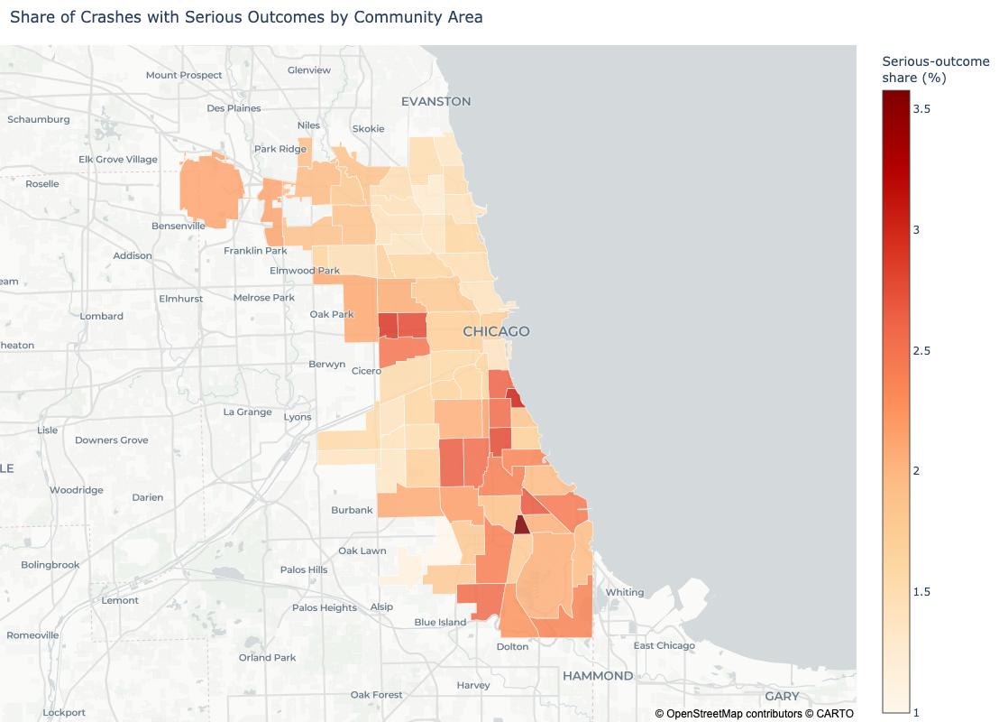

In [31]:
# Map the serious-outcome share by community area.
serious_share_map = community_areas.merge(
    serious_area_summary, on=["community_number", "community_name"], how="left", validate="one_to_one"
)
print("Community areas:", len(community_areas))
print("Areas without a serious-outcome share:", serious_share_map["serious_crash_share_pct"].isna().sum())
save_map(area_choropleth(
    serious_share_map, "serious_crash_share_pct", "Share of Crashes with Serious Outcomes by Community Area",
    "OrRd", "Serious-outcome share (%)", value_format=".2f",
    extra={"serious_crashes": ("Serious-outcome crashes", ",.0f"),
           "crashes_with_known_outcomes": ("Crashes with known outcomes", ",.0f")}
), "serious_share_by_area", "Chicago serious-outcome share by community area")

**Interpretation:**

Citywide, 16,023 of 875,925 crashes with known outcomes involved a serious outcome (**about 1.83%**).

- **Serious-outcome counts (table above):** They follow the total-crash pattern. **Austin (867)** leads, followed by the **Near West Side (692)**, **Near North Side (549)**, **Loop (487)**, **West Town (457)**, **Greater Grand Crossing (442)**, **Humboldt Park (408)**, **North Lawndale (392)**, **Auburn Gresham (359)** and **West Englewood (342)**.
- **Serious-outcome share map:** It shows a different geography. The highest shares are on the **West Side** (West Garfield Park 2.89%, East Garfield Park 2.78%) and the **South Side** (Washington Park 2.77%, Avalon Park 2.69%, West Englewood 2.66%, Englewood 2.54%). The darkest polygon, at about 3.5%, is a small far South Side community area that appears to be Burnside. The North Side lakefront and the far Northwest and Southwest Sides have the lowest shares.
- **Areas that stand out in both:** **West Garfield Park** (11th by count, 2.89%), **West Englewood** (10th, 2.66%), **North Lawndale** (8th, 2.48%, share rank 12) and **Greater Grand Crossing** (6th, 2.40%, share rank 14) are high on both measures. **Austin** is first by count and above the citywide share (2.10%, rank 22).
- **Areas that stand out on only one measure:**
  - *High serious count, average or low share (downtown):* Near North Side (3rd by count; share 1.41%, rank 65), Near West Side (1.71%, rank 43), Loop (1.72%, rank 42) and West Town (1.79%, rank 39). Their many serious crashes come mainly from their very large number of crashes overall.
  - *High share, modest serious count:* **East Garfield Park, Washington Park, Avalon Park and Englewood** (about 145–290 serious crashes each).
- **Serious outcomes per mile driven (Section 6.2):** Relative to traffic, serious-outcome crashes are most frequent in **West Garfield Park (65.9 per 100 million vehicle-miles, rank 1)**, **East Garfield Park (42.6)**, **Greater Grand Crossing (42.4)**, **Grand Boulevard (38.5)** and **Fuller Park (37.3)**. That is roughly two to three times the citywide level of about 20. Austin (35.1, rank 7), Chatham (34.9) and the Near West Side (33.7) follow. The Near North Side (23.7, rank 24) drops well down once traffic is considered. The exposure-adjusted view therefore confirms the share map: serious risk is concentrated on the West and South Sides, while downtown's high serious counts mostly reflect its traffic volume.
- **Stability:** Shares from large denominators are precise. For Austin (867 of about 41,300 crashes), an approximate 95% margin of error is about ±0.14 percentage points. For Washington Park or Avalon Park (about 5,400–6,000 crashes) it is about ±0.4 points, and for the smallest areas (around 1,000–2,000 crashes) it can approach ±1 point. The very top of the share map, including the small far South Side area at about 3.5%, should therefore be treated as less certain than the differences between large areas. Differences of a few tenths of a percentage point between small areas should not be over-interpreted.

## 6. Community-area comparisons and population adjustment

This section brings the main measures together in one comparison table. Population-adjusted counts use one 2023 population estimate as the denominator for the full eight-year period. This is a preliminary comparison, not a true exposure-adjusted rate: it does not account for vehicle miles traveled, traffic volume, pedestrian activity, or cyclist activity, and it is not an individual resident's probability of being in a crash.

In [32]:
# Community-area comparison table: injury, fatal and serious-outcome counts and shares, and their ranks.
ranking_base = crash_area_unique.dropna(subset=["community_name"])
# Injury/fatal flags are True/False where the crash-level count is known and NA where it is missing.
ranking_base = ranking_base.assign(**{
    flag: ranking_base[col].gt(0).astype("boolean").where(ranking_base[col].notna())
    for flag, col in [("injury_crash", "injuries_total"), ("fatal_crash", "injuries_fatal")]})

ranking = ranking_base.groupby(["community_number", "community_name"]).agg(
    total_crashes=("crash_record_id", "nunique"),
    injury_crashes=("injury_crash", lambda s: int(s.eq(True).sum())),
    crashes_with_known_injury_data=("injury_crash", "count"),
    fatal_crashes=("fatal_crash", lambda s: int(s.eq(True).sum())),
    crashes_with_known_fatal_data=("fatal_crash", "count"),
).reset_index().merge(
    serious_area_summary[["community_number", "community_name", "crashes_with_known_outcomes", "serious_crashes",
                          "serious_crash_share_pct"]],
    on=["community_number", "community_name"], how="left", validate="one_to_one")
ranking["injury_crash_pct"] = ranking["injury_crashes"] / ranking["crashes_with_known_injury_data"].replace(0, np.nan) * 100
ranking["fatal_crash_pct"] = ranking["fatal_crashes"] / ranking["crashes_with_known_fatal_data"].replace(0, np.nan) * 100
for rank_col, value_col in [("frequency_rank", "total_crashes"), ("serious_count_rank", "serious_crashes"),
                            ("serious_share_rank", "serious_crash_share_pct")]:
    ranking[rank_col] = ranking[value_col].rank(method="min", ascending=False).astype("Int64")
display(ranking.sort_values(["frequency_rank", "serious_count_rank"])[[
    "community_name", "total_crashes", "injury_crashes", "fatal_crashes", "serious_crashes",
    "injury_crash_pct", "fatal_crash_pct", "serious_crash_share_pct",
    "frequency_rank", "serious_count_rank", "serious_share_rank"
]].head(20).round(2))

,community_name,total_crashes,injury_crashes,fatal_crashes,serious_crashes,injury_crash_pct,fatal_crash_pct,serious_crash_share_pct,frequency_rank,serious_count_rank,serious_share_rank
24,AUSTIN,41419,7153,52,867,17.3,0.13,2.1,1,1,22
27,NEAR WEST SIDE,40480,5945,30,692,14.71,0.07,1.71,2,2,43
7,NEAR NORTH SIDE,38885,5029,20,549,12.95,0.05,1.41,3,3,65
31,LOOP,28338,3816,20,487,13.49,0.07,1.72,4,4,42
23,WEST TOWN,25594,4029,13,457,15.78,0.05,1.79,5,5,39
18,BELMONT CRAGIN,22260,2913,17,330,13.11,0.08,1.49,6,12,60
21,LOGAN SQUARE,20435,3040,11,329,14.9,0.05,1.61,7,13,52
22,HUMBOLDT PARK,19739,3436,27,408,17.45,0.14,2.07,8,7,24
5,LAKE VIEW,19697,2660,13,315,13.53,0.07,1.6,9,15,53
68,GREATER GRAND CROSSING,18449,3787,25,442,20.59,0.14,2.4,10,6,14


### 6.1 Add population-adjusted comparisons

The 2023 population estimates were prepared in Notebook 1. This cell joins them to the area table and calculates average annual reported crashes per 1,000 residents over 2018–2025.

In [33]:
# Add 2023 community-area population (prepared in Notebook 1) and average annual crashes per 1,000 residents.
ranking["community_name"] = ranking["community_name"].astype("string").str.strip().str.upper()
ranking = ranking.merge(population, on="community_name", how="left", validate="one_to_one", indicator=True)
print("Population match status:")
display(ranking.pop("_merge").value_counts())
ranking["average_annual_crashes_per_1000_residents"] = ranking["total_crashes"] / N_YEARS / ranking["population"] * 1000
display(ranking.sort_values("average_annual_crashes_per_1000_residents", ascending=False)[[
    "community_name", "total_crashes", "population", "average_annual_crashes_per_1000_residents",
    "serious_crashes", "serious_crash_share_pct"
]].head(15).round(2))

Population match status:


_merge
both          77
left_only      0
right_only     0
Name: count, dtype: int64

,community_name,total_crashes,population,average_annual_crashes_per_1000_residents,serious_crashes,serious_crash_share_pct
36,FULLER PARK,3509,2186.0,200.65,75,2.14
31,LOOP,28338,38284.0,92.53,487,1.72
25,WEST GARFIELD PARK,11665,16345.0,89.21,336,2.89
68,GREATER GRAND CROSSING,18449,29052.0,79.38,442,2.4
27,NEAR WEST SIDE,40480,65370.0,77.41,692,1.71
44,AVALON PARK,5435,9492.0,71.57,146,2.69
67,ENGLEWOOD,11492,21337.0,67.32,291,2.54
56,ARCHER HEIGHTS,7315,13875.0,65.90,102,1.4
50,SOUTH DEERING,7910,15100.0,65.48,161,2.04
28,NORTH LAWNDALE,15855,30355.0,65.29,392,2.48


### 6.2 Exposure-adjusted ("dangerousness") rankings

This section ranks community areas by how dangerous it is to travel there, measured as crashes relative to traffic volume:

- **Crashes per million vehicle-miles travelled (primary "dangerousness" measure),** with approximate 95% intervals (Poisson).
- **Estimated chance that a 10-mile drive involves a reported crash,** per 10,000 drives.
- **Serious-outcome crashes per 100 million vehicle-miles.**
- **Pedestrian-involved crashes per million transit boardings** (pedestrian-activity indicator), and **cyclist-involved crashes per 10,000 bike-share trips** (2018–2019 crashes compared with 2018–2019 trips).

The per-resident measure from Section 6.1 is kept for comparison. Areas where less than half of the estimated VMT comes from measured counts are marked as lower-confidence.

Community areas ranked by exposure-adjusted crash rate (crashes per million vehicle-miles travelled):


,community_name,dangerousness_rank,crashes_per_million_vmt,rate_low_95,rate_high_95,chance_per_10k_drives,serious_per_100m_vmt,serious_vmt_rank,street_crashes,measured_vmt_share_pct,volume_confidence,frequency_rank,per_resident_rank
25,WEST GARFIELD PARK,1,22.88,22.47,23.30,3.90,65.91,1,11665,59.86,Higher,29,3
27,NEAR WEST SIDE,2,19.66,19.47,19.86,3.36,33.69,9,40390,73.03,Higher,2,5
43,CHATHAM,3,18.51,18.22,18.79,3.16,34.86,8,16033,49.31,Lower,16,11
68,GREATER GRAND CROSSING,4,17.74,17.49,18.00,3.03,42.37,3,18426,61.18,Higher,10,4
0,ROGERS PARK,5,17.67,17.33,18.01,3.02,23.94,23,10482,54.73,Higher,34,74
36,FULLER PARK,6,17.43,16.85,18.00,2.97,37.26,5,3508,70.44,Higher,71,1
24,AUSTIN,7,16.76,16.60,16.93,2.86,35.09,7,41419,56.12,Higher,1,18
7,NEAR NORTH SIDE,8,16.76,16.59,16.92,2.86,23.66,24,38877,70.57,Higher,3,17
33,ARMOUR SQUARE,9,16.12,15.68,16.55,2.75,26.48,18,5296,63.53,Higher,63,19
30,LOWER WEST SIDE,10,15.81,15.54,16.07,2.70,24.96,20,13615,72.00,Higher,21,20


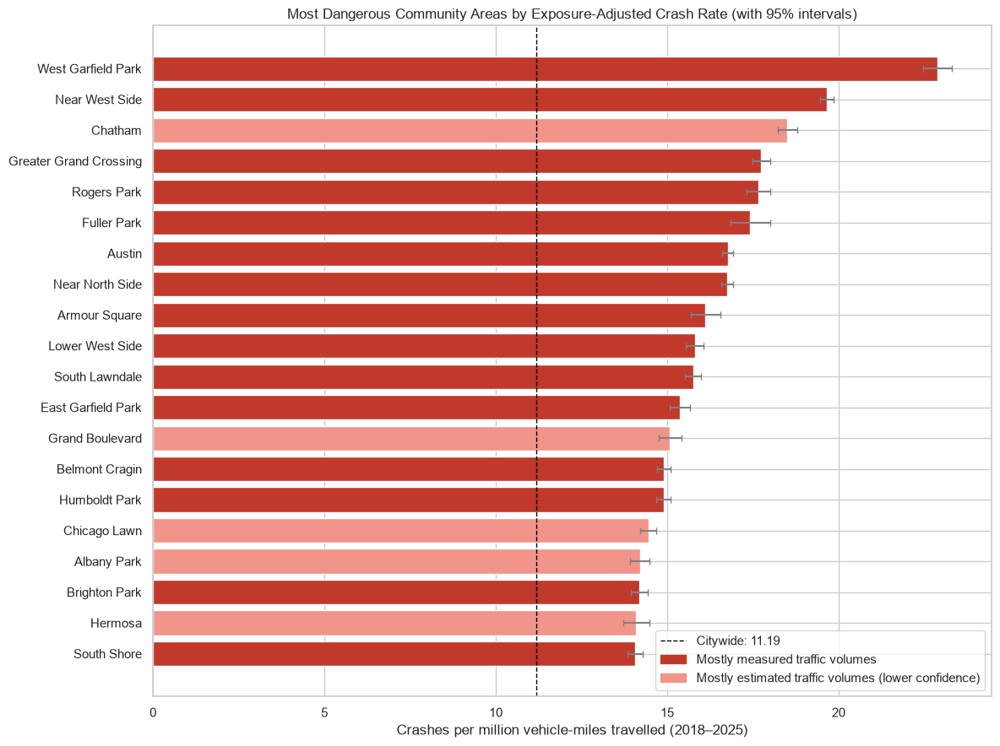

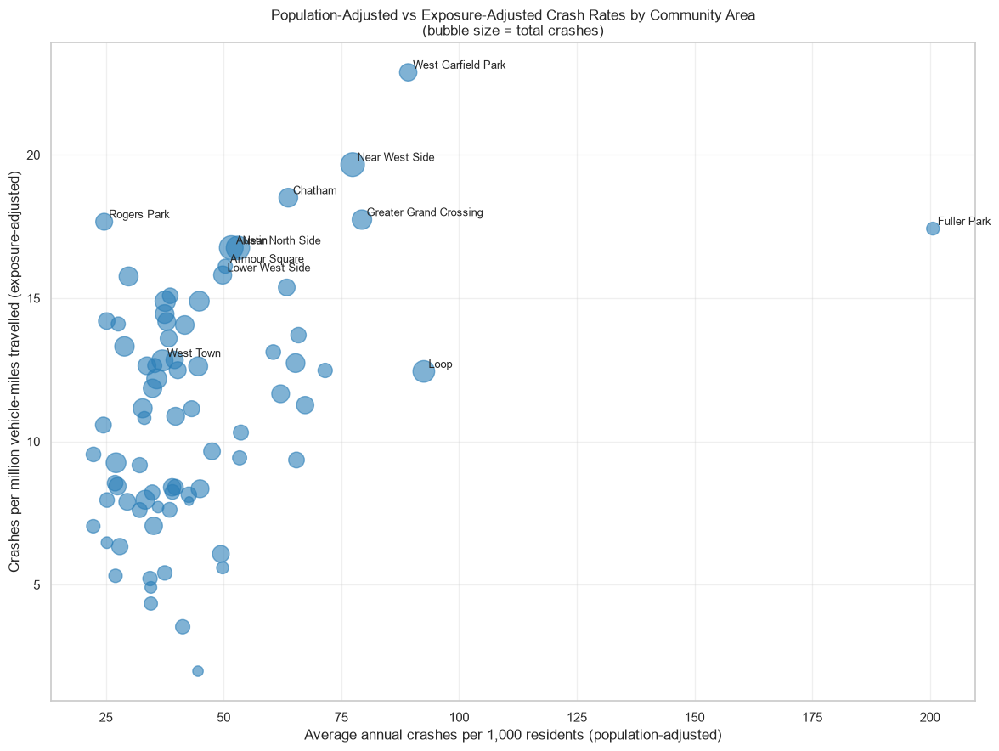

Pedestrian and cyclist exposure-adjusted rates (top 10 each):


,community_name,pedestrian_crashes,transit_daily_boardings,ped_crashes_per_million_boardings,pedestrian_rank
63,CLEARING,106,1442.00,25.16,1
74,MORGAN PARK,147,2844.70,17.68,2
71,BEVERLY,70,1359.50,17.62,3
1,WEST RIDGE,483,10437.90,15.84,4
51,EAST SIDE,70,1536.20,15.59,5
54,HEGEWISCH,25,579.20,14.77,6
29,SOUTH LAWNDALE,530,13811.86,13.13,7
11,FOREST GLEN,46,1202.60,13.09,8
73,MOUNT GREENWOOD,62,1726.90,12.29,9
25,WEST GARFIELD PARK,402,11491.35,11.97,10


,community_name,cyclist_crashes_2018_2019,divvy_trips_2018_2019,cyclist_crashes_per_10k_bikeshare_trips,cyclist_rank
1,WEST RIDGE,83.0,11431.0,72.61,1
13,ALBANY PARK,64.0,10980.0,58.29,2
20,AVONDALE,54.0,15322.0,35.24,3
15,IRVING PARK,70.0,23772.0,29.45,4
59,BRIDGEPORT,66.0,26834.0,24.60,5
41,WOODLAWN,33.0,23626.0,13.97,6
30,LOWER WEST SIDE,76.0,63005.0,12.06,7
21,LOGAN SQUARE,231.0,207970.0,11.11,8
0,ROGERS PARK,56.0,53076.0,10.55,9
76,EDGEWATER,78.0,81802.0,9.54,10


In [34]:
# Exposure-adjusted ("dangerousness") rates by community area. Numerators are crashes matched to modelled streets
# in the area; denominators are road-user exposure in the same area.
MIN_TRANSIT_BOARDINGS = 500   # average daily boardings needed before a pedestrian rate is shown
MIN_BIKESHARE_TRIPS = 10_000  # bike-share trips (2018–2019) needed before a cyclist rate is shown

# 1. Crash counts per area: all, serious, pedestrian-involved, and cyclist-involved in 2018–2019
#    (the years with bike-share data).
on_street = crash_road.loc[crash_road["on_modelled_street"]]
area_crashes = on_street.groupby("community_name").agg(
    street_crashes=("crash_record_id", "nunique"), street_serious=("serious_crash", "sum"),
    pedestrian_crashes=("pedestrian_involved", "sum"))
area_crashes["cyclist_crashes_2018_2019"] = (on_street.loc[on_street["cyclist_involved"]
                                                           & on_street["crash_date"].dt.year.isin([2018, 2019])]
                                             .groupby("community_name").size())
exposure_ranking = (ranking[["community_number", "community_name", "total_crashes", "serious_crashes", "population",
                             "average_annual_crashes_per_1000_residents", "frequency_rank"]]
                    .join(area_crashes, on="community_name")
                    .join(area_exposure, on="community_name")
                    .fillna({"cyclist_crashes_2018_2019": 0}))

# 2. Rates: crashes per million VMT (with approximate 95% Poisson intervals), per-drive probability, serious
#    crashes per 100 million VMT, pedestrian crashes per million transit boardings, cyclist crashes per 10,000
#    bike-share trips. Areas with too little activity for a stable pedestrian or cyclist rate are left blank.
vmt_millions = exposure_ranking["study_vmt"] / 1e6
n = exposure_ranking["street_crashes"]
exposure_ranking["crashes_per_million_vmt"] = n / vmt_millions
exposure_ranking["rate_low_95"] = (n - 1.96 * np.sqrt(n)).clip(lower=0) / vmt_millions
exposure_ranking["rate_high_95"] = (n + 1.96 * np.sqrt(n)) / vmt_millions
exposure_ranking["serious_per_100m_vmt"] = exposure_ranking["street_serious"] / (exposure_ranking["study_vmt"] / 1e8)
exposure_ranking["chance_per_10k_drives"] = drive_probability(n, exposure_ranking["study_vmt"])
exposure_ranking["ped_crashes_per_million_boardings"] = (
    exposure_ranking["pedestrian_crashes"] / (exposure_ranking["transit_daily_boardings"] * STUDY_DAYS / 1e6)
).where(exposure_ranking["transit_daily_boardings"] >= MIN_TRANSIT_BOARDINGS)
exposure_ranking["cyclist_crashes_per_10k_bikeshare_trips"] = (
    exposure_ranking["cyclist_crashes_2018_2019"] / (exposure_ranking["divvy_trips_2018_2019"] / 1e4)
).where(exposure_ranking["divvy_trips_2018_2019"] >= MIN_BIKESHARE_TRIPS)
exposure_ranking["volume_confidence"] = np.where(exposure_ranking["measured_vmt_share_pct"] >= 50, "Higher", "Lower")

# 3. Ranks (1 = highest) for each measure; sort by the exposure-adjusted crash rate.
for rank_col, value_col in [("dangerousness_rank", "crashes_per_million_vmt"),
                            ("serious_vmt_rank", "serious_per_100m_vmt"),
                            ("per_resident_rank", "average_annual_crashes_per_1000_residents"),
                            ("pedestrian_rank", "ped_crashes_per_million_boardings"),
                            ("cyclist_rank", "cyclist_crashes_per_10k_bikeshare_trips")]:
    exposure_ranking[rank_col] = exposure_ranking[value_col].rank(method="min", ascending=False).astype("Int64")
exposure_ranking = exposure_ranking.sort_values("dangerousness_rank")
citywide_rate = exposure_ranking["street_crashes"].sum() / (exposure_ranking["study_vmt"].sum() / 1e6)

# 4. Carry the exposure-adjusted rate and rank into the main comparison table (Section 6.3).
ranking = ranking.drop(columns=["crashes_per_million_vmt", "dangerousness_rank"], errors="ignore").merge(
    exposure_ranking[["community_name", "crashes_per_million_vmt", "dangerousness_rank"]],
    on="community_name", how="left")

print("Community areas ranked by exposure-adjusted crash rate (crashes per million vehicle-miles travelled):")
display(exposure_ranking[[
    "community_name", "dangerousness_rank", "crashes_per_million_vmt", "rate_low_95", "rate_high_95",
    "chance_per_10k_drives", "serious_per_100m_vmt", "serious_vmt_rank", "street_crashes",
    "measured_vmt_share_pct", "volume_confidence", "frequency_rank", "per_resident_rank"
]].head(20).round(2))

# 5. Chart: the 20 highest exposure-adjusted rates with 95% intervals (lighter bars = mostly estimated volumes).
top20 = exposure_ranking.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(12, 9))
ax.barh(top20["community_name"].str.title(), top20["crashes_per_million_vmt"],
        color=np.where(top20["volume_confidence"].eq("Higher"), "#c0392b", "#f1948a"),
        xerr=[top20["crashes_per_million_vmt"] - top20["rate_low_95"],
              top20["rate_high_95"] - top20["crashes_per_million_vmt"]], ecolor="grey", capsize=3)
citywide_line = ax.axvline(citywide_rate, color="black", linestyle="--", linewidth=1,
                           label=f"Citywide: {citywide_rate:.2f}")
ax.set(xlabel="Crashes per million vehicle-miles travelled (2018–2025)",
       title="Most Dangerous Community Areas by Exposure-Adjusted Crash Rate (with 95% intervals)")
ax.legend(handles=[citywide_line, Patch(color="#c0392b", label="Mostly measured traffic volumes"),
                   Patch(color="#f1948a", label="Mostly estimated traffic volumes (lower confidence)")],
          loc="lower right")
plt.tight_layout()
save_chart("dangerousness_bar")

# 6. Chart: per-resident vs per-vehicle-mile rates, labelling the top areas on each view.
fig, ax = plt.subplots(figsize=(12, 9))
ax.scatter(exposure_ranking["average_annual_crashes_per_1000_residents"], exposure_ranking["crashes_per_million_vmt"],
           s=np.sqrt(exposure_ranking["total_crashes"]) * 2, alpha=0.6, color="#2c7fb8")
label_areas = pd.concat([exposure_ranking.head(10), exposure_ranking.nsmallest(5, "per_resident_rank"),
                         exposure_ranking.nsmallest(5, "frequency_rank")]).drop_duplicates("community_name")
for _, row in label_areas.iterrows():
    ax.annotate(row["community_name"].title(),
                (row["average_annual_crashes_per_1000_residents"], row["crashes_per_million_vmt"]),
                fontsize=9, xytext=(4, 3), textcoords="offset points")
ax.set(xlabel="Average annual crashes per 1,000 residents (population-adjusted)",
       ylabel="Crashes per million vehicle-miles travelled (exposure-adjusted)",
       title="Population-Adjusted vs Exposure-Adjusted Crash Rates by Community Area\n(bubble size = total crashes)")
ax.grid(alpha=0.3)
plt.tight_layout()
save_chart("resident_vs_vmt_scatter")

# 7. Pedestrian and cyclist rates: top 10 areas on each.
print("Pedestrian and cyclist exposure-adjusted rates (top 10 each):")
display(exposure_ranking.sort_values("ped_crashes_per_million_boardings", ascending=False)[[
    "community_name", "pedestrian_crashes", "transit_daily_boardings", "ped_crashes_per_million_boardings",
    "pedestrian_rank"]].head(10).round(2))
display(exposure_ranking.sort_values("cyclist_crashes_per_10k_bikeshare_trips", ascending=False)[[
    "community_name", "cyclist_crashes_2018_2019", "divvy_trips_2018_2019", "cyclist_crashes_per_10k_bikeshare_trips",
    "cyclist_rank"]].head(10).round(2))

**Interpretation:**

- **Most dangerous areas per mile driven** (citywide: 11.19 crashes per million vehicle-miles):
  - **West Garfield Park:** 22.88 (about 3.9 crash involvements per 10,000 ten-mile drives)
  - **Near West Side:** 19.66 (about 3.4)
  - **Chatham:** 18.51 (about 3.2)
  - **Greater Grand Crossing:** 17.74 (about 3.0)
  - **Rogers Park:** 17.67 (about 3.0)
  - The 95% ranges are narrow (within about ±0.4 of each rate), so the top three are clearly separated; Greater Grand Crossing and Rogers Park are effectively tied.
- **How the ranking changes:** 4 of the 10 most dangerous areas per vehicle-mile are also in the top 10 by total crashes, and 4 are in the top 10 per resident. The rank correlation between the per-resident and per-vehicle-mile measures is 0.37, so adjusting for traffic substantially changes which areas look most dangerous.
- **Biggest changes once traffic is taken into account:**
  - *Much higher per mile driven than by crash count:* Fuller Park (71st by count → 6th per mile), Armour Square (63rd → 9th) and Hermosa (66th → 19th). These areas have more crashes than their traffic would suggest.
  - *Much lower per mile driven than by crash count:* Lincoln Park (15th → 58th), Lake View (9th → 47th) and Ashburn (27th → 65th). These areas have many crashes mainly because a lot of traffic passes through them.
- **Lower-confidence results:** Chatham ranks in the top 10 but relies mostly on estimated (not counted) traffic volumes, so the rate is less certain than for areas with mostly measured volumes.
- **Pedestrians and cyclists:** relative to transit boardings, pedestrian crash rates are highest in Clearing, Morgan Park and Beverly; relative to bike-share trips, cyclist crash rates are highest in West Ridge, Albany Park and Avondale. These use transit boardings and 2018–2019 bike-share trips as activity indicators, so they are best read as flags for further study, not precise per-person risks.

### 6.3 Final comparison table

This table identifies areas that appear in more than one high-priority category:

- A **high total count** indicates a larger number of reported crashes.
- A **high serious-outcome share** indicates a larger proportion among crashes with known outcomes.
- A **high population-adjusted count** compares reported crashes with resident population.
- A **high exposure-adjusted rate** compares crashes with the traffic actually travelling in the area.

In [35]:
# Final comparison table: counts, shares, population- and exposure-adjusted rates, and ranks for each area.
display(ranking.sort_values(["frequency_rank", "serious_count_rank"])[[
    "community_name", "total_crashes", "injury_crashes", "fatal_crashes", "serious_crashes",
    "serious_crash_share_pct", "average_annual_crashes_per_1000_residents",
    "crashes_per_million_vmt", "frequency_rank", "serious_count_rank", "serious_share_rank", "dangerousness_rank"
]].head(20).round(2))

,community_name,total_crashes,injury_crashes,fatal_crashes,serious_crashes,serious_crash_share_pct,average_annual_crashes_per_1000_residents,crashes_per_million_vmt,frequency_rank,serious_count_rank,serious_share_rank,dangerousness_rank
24,AUSTIN,41419,7153,52,867,2.1,51.63,16.76,1,1,22,7
27,NEAR WEST SIDE,40480,5945,30,692,1.71,77.41,19.66,2,2,43,2
7,NEAR NORTH SIDE,38885,5029,20,549,1.41,53.04,16.76,3,3,65,8
31,LOOP,28338,3816,20,487,1.72,92.53,12.45,4,4,42,33
23,WEST TOWN,25594,4029,13,457,1.79,37.01,12.83,5,5,39,26
18,BELMONT CRAGIN,22260,2913,17,330,1.49,37.61,14.90,6,12,60,14
21,LOGAN SQUARE,20435,3040,11,329,1.61,35.80,12.19,7,13,52,34
22,HUMBOLDT PARK,19739,3436,27,408,2.07,44.85,14.90,8,7,24,15
5,LAKE VIEW,19697,2660,13,315,1.6,27.16,9.26,9,15,53,48
68,GREATER GRAND CROSSING,18449,3787,25,442,2.4,79.38,17.74,10,6,14,4


**Areas appearing in more than one high-priority category (population-based measures)**

For this comparison, "high priority" means ranking in the **top 15 of the 77 community areas** on a measure. Four measures are used: total crashes, serious-outcome crashes, serious-outcome share, and average annual crashes per 1,000 residents. Values come from the tables in Sections 4.4, 5, 6.1 and 6.3. The code cell after this discussion repeats the comparison automatically with the exposure-adjusted measure (crashes per vehicle-mile) added as a fifth category.

| Community area | Total crashes (rank) | Serious-outcome crashes (rank) | Serious-outcome share (rank) | Avg. annual crashes per 1,000 residents (rank) | Categories (of 4) |
|---|---|---|---|---|---|
| **Greater Grand Crossing** | 18,449 (#10) | 442 (#6) | 2.40% (#14) | 79.4 (#4) | **4** |
| **North Lawndale** | 15,855 (#17) | 392 (#8) | 2.48% (#12) | 65.3 (#10) | **3** |
| **West Garfield Park** | 11,665 (outside top 20) | 336 (#11) | 2.89% (top 11) | 89.2 (#3) | **3** |
| **West Englewood** | 12,905 (outside top 20) | 342 (#10) | 2.66% (top 11) | 62.1 (#13) | **3** |
| **Loop** | 28,338 (#4) | 487 (#4) | 1.72% (#42) | 92.5 (#2) | **3** |
| **Near West Side** | 40,480 (#2) | 692 (#2) | 1.71% (#43) | 77.4 (#5) | **3** |
| Austin | 41,419 (#1) | 867 (#1) | 2.10% (#22) | 51.6 (just outside top 15) | 2 |
| Near North Side | 38,885 (#3) | 549 (#3) | 1.41% (#65) | 53.0 (just outside top 15) | 2 |

**Other areas in exactly two categories:**

- **High count and high serious count:** West Town, Humboldt Park, Auburn Gresham, Belmont Cragin, Logan Square, Lake View, and Portage Park.
- **High serious-outcome share and high crashes per resident:** Englewood (2.54%; 67.3 per 1,000), East Garfield Park (2.78%; 63.4), Washington Park (2.77%; 60.6), and Avalon Park (2.69%; 71.6).

**Interpretation:**

- **Greater Grand Crossing is the only area in all four categories.** It combines a large number of crashes, a large number and above-average share of serious outcomes, and a high crash count relative to its population.
- **North Lawndale, West Garfield Park and West Englewood** are high on serious count, serious share and population-adjusted crashes. Their *total* crash counts are moderate, so they would be missed by a ranking based on volume alone. Together with Greater Grand Crossing, they form the clearest group of South and West Side areas where serious outcomes are both frequent and proportionally high.
- **The Loop and Near West Side** appear in three categories, but all three reflect *volume*: high totals, high serious counts and high crashes per resident. Their serious-outcome share is below the citywide 1.83%. Their per-resident values are also inflated by large numbers of workers, visitors and through-travellers who are not counted as residents.
- **Austin** is first on both count measures, has an above-average serious share (2.10%), and falls just outside the top 15 per resident, so it remains a priority because of its sheer volume.
- **With traffic taken into account (table below):**
  - *Highest priority:* Greater Grand Crossing is in the top 15 on all five measures, including 4th per vehicle-mile. West Garfield Park (1st per vehicle-mile) and the Near West Side (2nd) are in four of the five.
  - *Newly identified:* Chatham (3rd per vehicle-mile) appears only once traffic is considered.
  - *Less urgent than they first appear:* North Lawndale, West Englewood and the Loop are not in the top 15 per vehicle-mile. North Lawndale's rate (12.74) and the Loop's (12.45) are close to the citywide 11.19, so their high per-resident numbers mostly reflect how much traffic they carry, not riskier travel.
- **Fuller Park** has by far the highest population-adjusted value (200.7 per 1,000) but appears in only that one category. With about 2,200 residents and 3,509 crashes, that figure is driven by a very small denominator and should not be read as a high-risk finding on its own.

In [36]:
# Areas in the top 15 on two or more of the five measures (cells show the area's rank on each qualifying measure).
TOP_N = 15
category_ranks = pd.DataFrame({
    "High total count": ranking["frequency_rank"],
    "High serious-outcome count": ranking["serious_count_rank"],
    "High serious-outcome share": ranking["serious_share_rank"],
    "High crashes per resident": ranking["average_annual_crashes_per_1000_residents"].rank(method="min", ascending=False),
    "High crashes per vehicle-mile": ranking["dangerousness_rank"],
}).astype("Float64")
category_ranks.index = ranking["community_name"].str.title()
category_flags = category_ranks.le(TOP_N).fillna(False)

multi_category = category_ranks.astype("Int64").astype("string").where(category_flags, "")
multi_category["categories (of 5)"] = category_flags.sum(axis=1)
# Sort by number of categories, then by exposure-adjusted rank.
order = (pd.DataFrame({"n": multi_category["categories (of 5)"],
                       "vmt_rank": category_ranks["High crashes per vehicle-mile"].fillna(999)})
         .sort_values(["n", "vmt_rank"], ascending=[False, True]).index)
multi_category = multi_category.loc[order]
print(f"Areas in the top {TOP_N} on two or more measures (cells show the area's rank on each qualifying measure):")
display(multi_category.loc[multi_category["categories (of 5)"] >= 2])

Areas in the top 15 on two or more measures (cells show the area's rank on each qualifying measure):


,High total count,High serious-outcome count,High serious-outcome share,High crashes per resident,High crashes per vehicle-mile,categories (of 5)
community_name,,,,,,
Greater Grand Crossing,10,6,14,4,4,5
West Garfield Park,,11,3,3,1,4
Near West Side,2,2,,5,2,4
Austin,1,1,,,7,3
Near North Side,3,3,,,8,3
East Garfield Park,,,4,12,12,3
Belmont Cragin,6,12,,,14,3
Humboldt Park,8,7,,,15,3
North Lawndale,,8,12,10,,3


## 7. Which intersections and street corridors stand out?

This section lists the specific intersections and half-mile corridors with the most reported crashes, the most serious-outcome crashes, and the highest crash rates relative to traffic. The map shows the top 25 on each list. Intersection lists are shown by default; corridor lists can be switched on in the legend. Hover for names, counts, traffic and rates.

Intersections with the most reported crashes (2018–2025):


,intersection_name,community_name,crashes,serious_crashes,fatal_crashes,pedestrian_crashes,entering_adt,crashes_per_mev,serious_per_100mev
1,E Lake Shore Dr & N Lake Shore Dr,Near North Side,1059.0,21.0,2.0,2.0,6000.00,60.40,119.78
2,E 95th St & S Stony Island Ave,South Deering,987.0,16.0,3.0,12.0,83873.74,4.03,6.53
3,E Chicago Ave & N Lake Shore Dr,Near North Side,703.0,13.0,0.0,3.0,65525.00,3.67,6.79
4,S Halsted St & W 99th St,Washington Heights,679.0,11.0,0.0,10.0,42252.54,5.50,8.91
5,E Museum Dr & S Columbia Dr,Hyde Park,672.0,22.0,0.0,3.0,3300.00,69.69,228.15
6,E 79th St & S Stony Island Ave W,Avalon Park,654.0,15.0,1.0,9.0,27990.98,8.00,18.34
7,E 87th St & S State St & W 87th St,Chatham,640.0,12.0,1.0,18.0,45739.49,4.79,8.98
8,E 79th St & S South Chicago Ave & S Stony Island Ave,South Chicago,629.0,15.0,1.0,7.0,44056.62,4.89,11.65
9,E Lake Shore Dr & E Oak St & N Lake Shore Dr,Near North Side,549.0,11.0,0.0,5.0,29050.00,6.47,12.96
10,S Canal St & W Roosevelt Rd,Near West Side,538.0,10.0,0.0,19.0,44926.27,4.10,7.62


Intersections with the most serious-outcome crashes:


,intersection_name,community_name,crashes,serious_crashes,fatal_crashes,pedestrian_crashes,entering_adt,crashes_per_mev,serious_per_100mev
1,E Museum Dr & S Columbia Dr,Hyde Park,672.0,22.0,0.0,3.0,3300.00,69.69,228.15
2,E Lake Shore Dr & N Lake Shore Dr,Near North Side,1059.0,21.0,2.0,2.0,6000.00,60.40,119.78
3,E 95th St & S Stony Island Ave,South Deering,987.0,16.0,3.0,12.0,83873.74,4.03,6.53
4,S Wentworth Ave & W Marquette Rd,Englewood,383.0,16.0,0.0,4.0,24200.00,5.42,22.63
5,E 79th St & S Stony Island Ave W,Avalon Park,654.0,15.0,1.0,9.0,27990.98,8.00,18.34
6,E 79th St & S South Chicago Ave & S Stony Island Ave,South Chicago,629.0,15.0,1.0,7.0,44056.62,4.89,11.65
7,S Cicero Ave & W Lexington St,Austin,355.0,15.0,1.0,16.0,37808.54,3.21,13.58
8,S Desplaines St & W Taylor St,Near West Side,349.0,14.0,0.0,1.0,17869.06,6.68,26.81
9,E 71st St & S State St & W 71st St,Greater Grand Crossing,334.0,14.0,2.0,8.0,21450.00,5.33,22.34
10,E Chicago Ave & N Lake Shore Dr,Near North Side,703.0,13.0,0.0,3.0,65525.00,3.67,6.79


Highest-risk intersections relative to traffic (crashes per million entering vehicles; at least 30 crashes and measured volume on 2+ legs):


,intersection_name,community_name,crashes,serious_crashes,fatal_crashes,pedestrian_crashes,entering_adt,crashes_per_mev,serious_per_100mev
1,N Halsted St & W Hubbard St,West Town,408.0,4.0,0.0,4.0,7474.13,18.68,18.32
2,N Homan Ave & W Grand Ave,Humboldt Park,203.0,0.0,0.0,0.0,7050.00,9.85,0.00
3,E Illinois St & N Peshtigo Ct,Near North Side,145.0,1.0,0.0,5.0,5493.46,9.03,6.23
4,E Grand Ave & N Streeter Dr,Near North Side,259.0,1.0,0.0,5.0,10525.00,8.42,3.25
5,E 79th St & S Stony Island Ave W,Avalon Park,654.0,15.0,1.0,9.0,27990.98,8.00,18.34
6,E 48th St & S Michigan Ave,Grand Boulevard,159.0,1.0,0.0,0.0,7300.00,7.45,4.69
7,E 63rd St & S State St & W 63rd St,Greater Grand Crossing,426.0,8.0,0.0,8.0,20167.82,7.23,13.58
8,E 79th St & S Cottage Grove Ave,Greater Grand Crossing,359.0,11.0,1.0,36.0,17006.30,7.22,22.14
9,E 67th St & S Jeffery Blvd & S Jeffery Dr,South Shore,364.0,2.0,0.0,11.0,17400.00,7.16,3.93
10,S Kostner Ave & W Congress Pkwy,West Garfield Park,215.0,5.0,1.0,3.0,10375.00,7.09,16.49


... (2 outputs left out)

Half-mile street corridors with the most serious-outcome crashes:


,corridor_name,community_name,road_class,crashes,serious_crashes,fatal_crashes,pedestrian_crashes,avg_daily_volume,crashes_per_million_vmt,serious_per_100m_vmt,measured_vmt_share_pct
1,5600–5999 S Lake Shore Dr,Hyde Park,Lake Shore Drive,1041.0,33.0,1.0,5.0,53600.00,14.19,45.00,100.00
2,0–399 W 87th St,Chatham,Arterial,2304.0,30.0,4.0,83.0,27053.21,58.45,76.11,100.00
3,0–399 W 63rd St,Englewood,Arterial,723.0,26.0,0.0,29.0,13205.59,37.49,134.80,100.00
4,0–399 W 79th St,Chatham,Arterial,985.0,24.0,4.0,48.0,13889.58,48.47,118.10,100.00
5,8400–8799 S Cottage Grove Ave,Chatham,Arterial,602.0,24.0,4.0,31.0,13776.50,29.73,118.54,100.00
6,1200–1599 N Lake Shore Dr,Near North Side,Lake Shore Drive,676.0,22.0,3.0,8.0,7050.00,64.93,211.31,100.00
7,800–1199 N Pulaski Rd,Humboldt Park,Arterial,530.0,21.0,1.0,20.0,22165.14,16.23,64.31,100.00
8,0–399 E Lake Shore Dr,Near North Side,Lake Shore Drive,1013.0,20.0,2.0,2.0,6000.00,262.29,517.84,100.00
9,0–399 W Marquette Rd,Greater Grand Crossing,Collector,633.0,19.0,0.0,6.0,22798.08,18.90,56.73,100.00
10,400–799 S Cicero Ave,Austin,Arterial,548.0,19.0,0.0,31.0,24981.02,22.98,79.69,100.00


Highest-risk corridors relative to traffic (crashes per million vehicle-miles; mostly measured volume, at least 30 crashes):


,corridor_name,community_name,road_class,crashes,serious_crashes,fatal_crashes,pedestrian_crashes,avg_daily_volume,crashes_per_million_vmt,serious_per_100m_vmt,measured_vmt_share_pct
1,0–399 W Hubbard St,Near North Side,Local street,562.0,4.0,0.0,17.0,3750.00,93.98,66.89,100.00
2,0–399 S Canal St,Near West Side,Local street,387.0,1.0,0.0,11.0,5100.00,73.48,18.99,100.00
3,2800–3199 W Harrison St,East Garfield Park,Collector,364.0,12.0,0.0,14.0,3500.00,70.28,231.71,100.00
4,0–399 W Kinzie St,Near North Side,Collector,656.0,4.0,0.0,31.0,4818.39,68.61,41.83,100.00
5,800–1199 S Canal St,Near West Side,Collector,707.0,8.0,0.0,26.0,12900.00,56.87,64.35,100.00
6,4400–4799 W Harrison St,West Garfield Park,Collector,332.0,11.0,1.0,6.0,4229.82,52.26,173.14,100.00
7,0–399 N Clinton St,Near West Side,Local street,287.0,6.0,0.0,10.0,3803.34,51.97,108.65,100.00
8,1200–1599 E 53rd St,Hyde Park,Local street,667.0,8.0,1.0,24.0,8850.00,48.98,58.74,100.00
9,0–399 N Green St,Near West Side,Local street,261.0,2.0,0.0,9.0,3634.10,48.94,37.50,82.98
10,0–399 E Chicago Ave,Near North Side,Arterial,943.0,10.0,1.0,32.0,11754.71,47.74,50.62,100.00


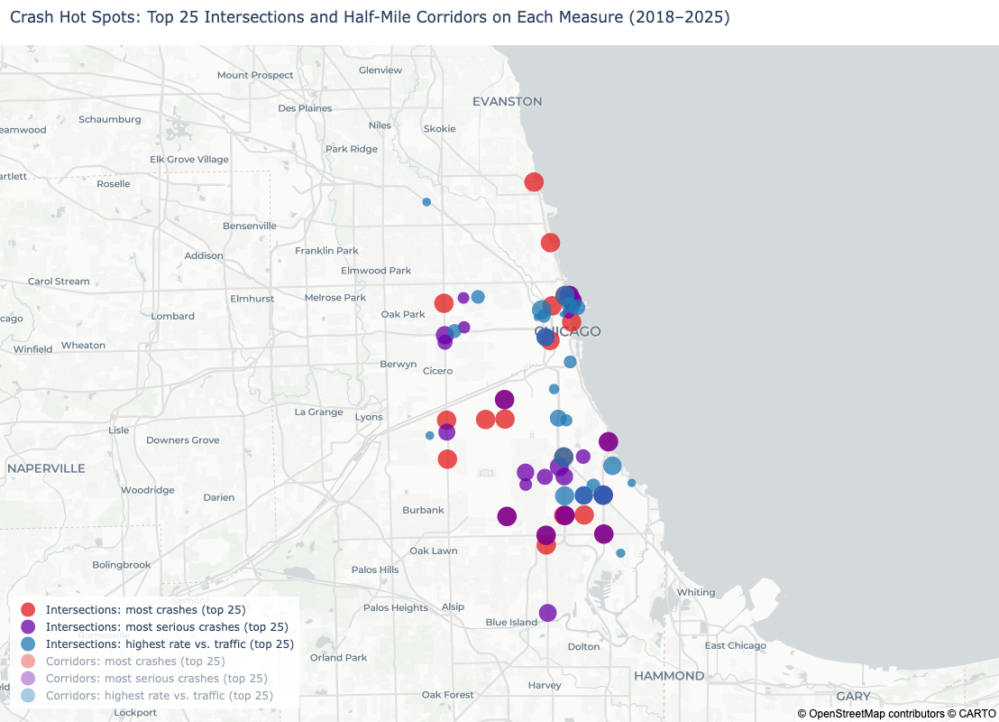

62.6% of geocoded crashes occurred at intersections; the 100 highest-count intersections account for 4.6% of all geocoded crashes.


In [37]:
# Specific intersections and half-mile corridors with the most crashes, the most serious outcomes,
# and the highest exposure-adjusted rates.
pd.set_option("display.max_colwidth", 60)

int_cols = ["intersection_name", "community_name", "crashes", "serious_crashes", "fatal_crashes",
            "pedestrian_crashes", "entering_adt", "crashes_per_mev", "serious_per_100mev"]
corr_cols = ["corridor_name", "community_name", "road_class", "crashes", "serious_crashes", "fatal_crashes",
             "pedestrian_crashes", "avg_daily_volume", "crashes_per_million_vmt", "serious_per_100m_vmt",
             "measured_vmt_share_pct"]


# 1. Top-15 tables for each measure (rate tables include only locations with a reliable rate).
def show_top(frame, cols, sort_col, label, n=15, reliable_only=False):
    """Print a label and the top n rows, ranked by sort_col (ties broken by crash count), with readable names."""
    table = frame.loc[frame["rate_reliable"]] if reliable_only else frame
    table = table.sort_values(list(dict.fromkeys([sort_col, "crashes"])), ascending=False).head(n)[cols].copy()
    for col in cols[:2]:
        table[col] = table[col].map(street_title)
    print(label)
    display(table.reset_index(drop=True).rename(index=lambda i: i + 1).round(2))


show_top(intersections, int_cols, "crashes", "Intersections with the most reported crashes (2018–2025):")
show_top(intersections, int_cols, "serious_crashes", "Intersections with the most serious-outcome crashes:")
show_top(intersections, int_cols, "crashes_per_mev",
         f"Highest-risk intersections relative to traffic (crashes per million entering vehicles; "
         f"at least {MIN_RATE_CRASHES} crashes and measured volume on 2+ legs):", reliable_only=True)
show_top(corridors, corr_cols, "crashes", "Half-mile street corridors with the most reported crashes:")
show_top(corridors, corr_cols, "serious_crashes", "Half-mile street corridors with the most serious-outcome crashes:")
show_top(corridors, corr_cols, "crashes_per_million_vmt",
         "Highest-risk corridors relative to traffic (crashes per million vehicle-miles; mostly measured volume, "
         f"at least {MIN_RATE_CRASHES} crashes):", reliable_only=True)

# 2. Map: the top 25 intersections and corridors on each list, coloured by list (corridors start hidden).
lists = {
    "Most crashes": ("crashes", False), "Most serious crashes": ("serious_crashes", False),
    "Highest rate vs. traffic": (None, True),
}
hotspot_fig = go.Figure()
palette = {"Most crashes": "#e31a1c", "Most serious crashes": "#6a00a8", "Highest rate vs. traffic": "#1f78b4"}
for kind, frame, rate_col, symbol_label, name_col, volume_col, volume_label in [
    ("Intersection", intersections, "crashes_per_mev", "per million entering vehicles", "intersection_name",
     "entering_adt", "Vehicles entering per day"),
    ("Corridor", corridors, "crashes_per_million_vmt", "per million vehicle-miles", "corridor_name",
     "avg_daily_volume", "Average daily traffic"),
]:
    for list_name, (sort_col, reliable) in lists.items():
        table = frame.loc[frame["rate_reliable"]] if reliable else frame
        table = table.sort_values(sort_col or rate_col, ascending=False).head(25)
        hotspot_fig.add_trace(go.Scattermap(
            lat=table["lat"], lon=table["lon"], mode="markers",
            marker=dict(size=np.clip(np.sqrt(table["crashes"]) * 1.1, 7, 22), color=palette[list_name], opacity=0.75),
            customdata=np.column_stack([
                table[name_col].map(street_title), table["community_name"].fillna("").map(street_title),
                table["crashes"].astype(int), table["serious_crashes"].astype(int),
                table[volume_col].round(0), table[rate_col].round(2)]),
            hovertemplate=(f"<b>%{{customdata[0]}}</b> ({kind.lower()})<br>%{{customdata[1]}}<br>"
                           "Crashes: %{customdata[2]:,} (serious: %{customdata[3]:,})<br>"
                           f"{volume_label}: %{{customdata[4]:,.0f}}<br>"
                           f"Crashes {symbol_label}: %{{customdata[5]:.2f}}<extra>{list_name}</extra>"),
            name=f"{kind}s: {list_name.lower()} (top 25)", visible=True if kind == "Intersection" else "legendonly",
        ))
hotspot_fig.update_layout(
    title=dict(text="Crash Hot Spots: Top 25 Intersections and Half-Mile Corridors on Each Measure (2018–2025)", x=0.01),
    map=dict(style="carto-positron", center={"lat": 41.835, "lon": -87.69}, zoom=9.6),
    height=800, margin=dict(r=0, t=50, l=0, b=0),
    legend=dict(x=0.01, y=0.02, yanchor="bottom", bgcolor="rgba(255,255,255,0.85)"),
)
save_map(hotspot_fig, "hotspots", "Chicago crash hot spots")

# 3. How concentrated crashes are at intersections.
shares = crash_road["location_type"].value_counts(normalize=True) * 100
top_int_share = intersections.nlargest(100, "crashes")["crashes"].sum() / len(crash_road) * 100
print(f"{shares.get('Intersection', 0):.1f}% of geocoded crashes occurred at intersections; "
      f"the 100 highest-count intersections account for {top_int_share:.1f}% of all geocoded crashes.")

**Interpretation:**

- **Intersections:** 6 of the 15 highest-count intersections are also among the 15 with the most serious-outcome crashes (E Museum Dr & S Columbia Dr; E Lake Shore Dr & N Lake Shore Dr; E Chicago Ave & N Lake Shore Dr; E 79th St & S South Chicago Ave & S Stony Island Ave; E 79th St & S Stony Island Ave W; E 95th St & S Stony Island Ave). Some of the busiest intersections are also risky relative to their traffic: E 79th St & S Stony Island Ave W (654 crashes) has the fifth-highest rate of any intersection with a reliable rate.
- **Corridors:** 4 of the 15 highest-count half-mile corridors are also in the top 15 for serious-outcome crashes, and 1 is in the top 15 for crashes per vehicle-mile. No corridor is on all three lists, so count-based and rate-based priorities point to different places.
- **Concentration:** 62.6% of geocoded crashes occurred at intersections, and the 100 highest-count intersections alone account for 4.6% of all geocoded crashes.
- **Reading the lists:** high-count, high-volume locations affect the most people and suit capacity, signal-timing or enforcement responses. High-rate locations with moderate traffic point to design or operating conditions worth reviewing. Rates are shown only where they rest on at least 30 crashes and mostly measured traffic volumes, and not for locations next to a much busier road (such as Lake Shore Drive or an expressway interchange), whose crashes would otherwise be divided by the quieter street's traffic.

## 8. Interactive exposure-adjusted risk by area and time of week

This map estimates an individual driver's risk of being involved in a reported crash in a given community area during a given time window. For each area and window:

- **Exposure** = the area's VMT × the share of the area's travel that falls in that window. The share is estimated from ride-hail trip-miles starting in the area, blended with the citywide pattern for areas with few sampled trips.
- **Risk** = the estimated chance that a 10-mile drive involves a reported crash, shown per 10,000 drives and as "about 1 in N".

Use the dropdown menu to switch time windows. All windows use the same colour scale, so colours can be compared directly. The heatmap below the map shows the same estimate for the 25 highest-risk areas across all windows.

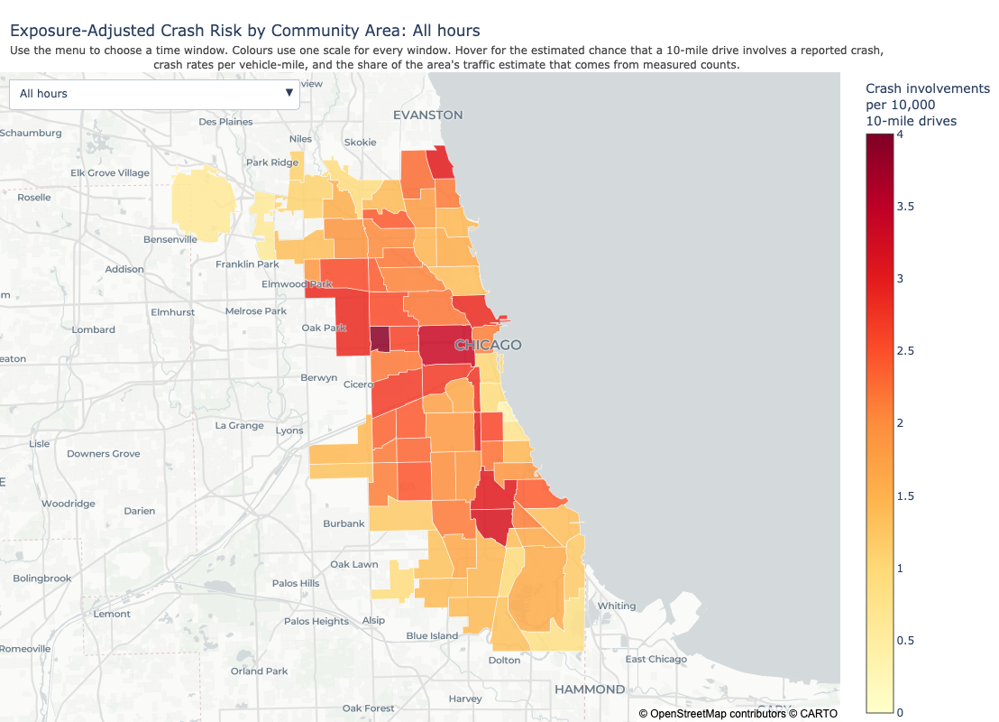

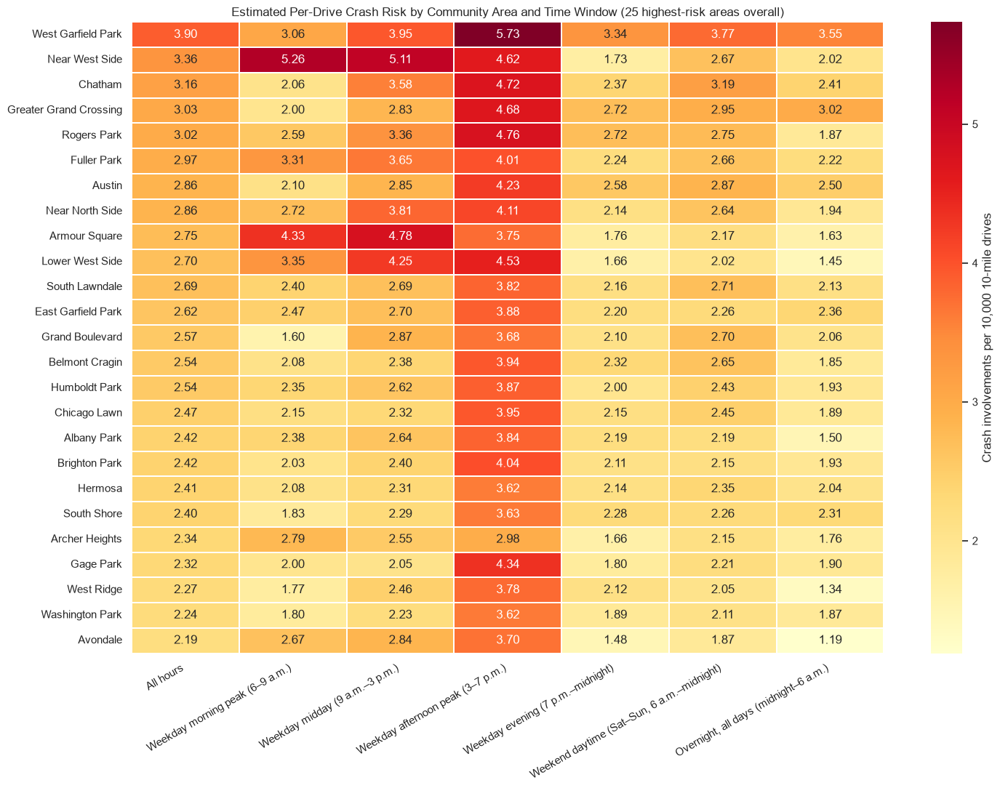

Citywide estimated per-drive risk by time window:


,crashes,chance_per_10k_drives,window_vmt_billions
window,,,
All hours,869915,1.91,77.73
Weekday morning peak (6–9 a.m.),87152,1.79,8.30
Weekday midday (9 a.m.–3 p.m.),207910,2.19,16.21
Weekday afternoon peak (3–7 p.m.),193648,2.88,11.48
Weekday evening (7 p.m.–midnight),100902,1.47,11.73
"Weekend daytime (Sat–Sun, 6 a.m.–midnight)",195359,1.73,19.29
"Overnight, all days (midnight–6 a.m.)",84944,1.35,10.71


In [38]:
# Interactive exposure-adjusted risk map by community area and time of week.
# Exposure in each area and time window = the area's VMT x the share of its travel that happens in that window.
# The time profile comes from ride-hail trip-miles starting in the area, blended with the citywide profile
# so that areas with few sampled trips are not driven by noise.
PROFILE_SMOOTHING_MILES = 20_000

TIME_WINDOWS = {
    "All hours": lambda d, h: np.ones(len(h), dtype=bool),
    "Weekday morning peak (6–9 a.m.)": lambda d, h: (d < 5) & (h >= 6) & (h < 9),
    "Weekday midday (9 a.m.–3 p.m.)": lambda d, h: (d < 5) & (h >= 9) & (h < 15),
    "Weekday afternoon peak (3–7 p.m.)": lambda d, h: (d < 5) & (h >= 15) & (h < 19),
    "Weekday evening (7 p.m.–midnight)": lambda d, h: (d < 5) & (h >= 19),
    "Weekend daytime (Sat–Sun, 6 a.m.–midnight)": lambda d, h: (d >= 5) & (h >= 6),
    "Overnight, all days (midnight–6 a.m.)": lambda d, h: h < 6,
}

# 1. Each area's share of travel in every weekday/hour cell, blended with the citywide pattern
#    (20,000 sampled trip-miles' worth of weight) so that thinly sampled areas are not driven by noise.
profile = (tnp.dropna(subset=["pickup_community_area", "day_index", "hour"])
           .assign(community_name=lambda t: t["pickup_community_area"].map(area_numbers))
           .dropna(subset=["community_name"])
           .groupby(["community_name", "day_index", "hour"])["trip_miles"].sum())
full_index = pd.MultiIndex.from_product([area_exposure.index, range(7), range(24)],
                                        names=["community_name", "day_index", "hour"])
profile = profile.reindex(full_index, fill_value=0).rename("trip_miles").reset_index()
city_share = hour_share.rename("city_share").reset_index()
profile = profile.merge(city_share, on=["day_index", "hour"], how="left")
area_miles = profile.groupby("community_name")["trip_miles"].transform("sum")
profile["share"] = ((profile["trip_miles"] + PROFILE_SMOOTHING_MILES * profile["city_share"])
                    / (area_miles + PROFILE_SMOOTHING_MILES))

# 2. For each time window: the area's share of travel, its exposure (VMT × share), crashes, and rates.
crash_times = on_street.assign(day_index=on_street["crash_date"].dt.dayofweek, hour=on_street["crash_date"].dt.hour)

window_rows = []
for window, rule in TIME_WINDOWS.items():
    in_window = rule(profile["day_index"].to_numpy(), profile["hour"].to_numpy())
    share = profile.loc[in_window].groupby("community_name")["share"].sum()
    in_window_crash = rule(crash_times["day_index"].to_numpy(), crash_times["hour"].to_numpy())
    counts = crash_times.loc[in_window_crash].groupby("community_name").agg(
        crashes=("crash_record_id", "nunique"), serious_crashes=("serious_crash", "sum"))
    rows = area_exposure[["study_vmt", "measured_vmt_share_pct"]].join(share.rename("time_share")).join(counts)
    rows["window"] = window
    window_rows.append(rows.reset_index())
area_time = pd.concat(window_rows, ignore_index=True).fillna({"crashes": 0, "serious_crashes": 0})
area_time["window_vmt"] = area_time["study_vmt"] * area_time["time_share"]
area_time["crashes_per_million_vmt"] = area_time["crashes"] / (area_time["window_vmt"] / 1e6)
area_time["serious_per_100m_vmt"] = area_time["serious_crashes"] / (area_time["window_vmt"] / 1e8)
area_time["chance_per_10k_drives"] = drive_probability(area_time["crashes"], area_time["window_vmt"])
area_time["one_in"] = (10_000 / area_time["chance_per_10k_drives"].replace(0, np.nan)).round(-1)
area_time["rank_in_window"] = (area_time.groupby("window")["chance_per_10k_drives"]
                               .rank(method="min", ascending=False).astype("Int64"))

# 3. Map: one layer per time window, on a common colour scale so windows can be compared directly.
risk_cmax = area_time["chance_per_10k_drives"].quantile(0.97)
n_areas = area_time["community_name"].nunique()

risk_fig = go.Figure()
windows = list(TIME_WINDOWS)
for i, window in enumerate(windows):
    w = area_time.loc[area_time["window"].eq(window)]
    risk_fig.add_trace(go.Choroplethmap(
        geojson=boundary_geojson, featureidkey="properties.community_name",
        locations=w["community_name"].astype(str), z=w["chance_per_10k_drives"],
        zmin=0, zmax=risk_cmax, colorscale="YlOrRd", visible=(i == 0),
        marker=dict(opacity=0.85, line=dict(width=0.6, color="white")),
        colorbar=dict(title=dict(text=f"Crash involvements<br>per 10,000<br>{TRIP_MILES}-mile drives")),
        customdata=np.column_stack([
            w["community_name"].map(street_title), w["chance_per_10k_drives"].round(2), w["one_in"],
            w["crashes_per_million_vmt"].round(2), w["serious_per_100m_vmt"].round(1),
            w["crashes"].astype(int), (w["window_vmt"] / 1e6).round(0), w["rank_in_window"],
            w["measured_vmt_share_pct"].round(0)]),
        hovertemplate=(
            "<b>%{customdata[0]}</b><br>"
            f"Chance a {TRIP_MILES}-mile drive involves a reported crash: "
            "%{customdata[1]:.2f} per 10,000 (about 1 in %{customdata[2]:,.0f})<br>"
            "Crashes per million vehicle-miles: %{customdata[3]:.2f}<br>"
            "Serious crashes per 100 million vehicle-miles: %{customdata[4]:.1f}<br>"
            "Crashes in this window: %{customdata[5]:,} over %{customdata[6]:,.0f} million vehicle-miles<br>"
            f"Rank in this window: %{{customdata[7]}} of {n_areas}<br>"
            "Share of VMT from measured counts: %{customdata[8]:.0f}%<extra></extra>"),
        name=window, showlegend=False,
    ))
risk_fig.update_layout(
    title=dict(text=f"Exposure-Adjusted Crash Risk by Community Area: {windows[0]}", x=0.01),
    map=dict(style="carto-positron", center={"lat": 41.835, "lon": -87.69}, zoom=9.6),
    height=800, margin=dict(r=0, t=80, l=0, b=0),
    updatemenus=[dict(
        buttons=[dict(label=w, method="update",
                      args=[{"visible": [j == i for j in range(len(windows))]},
                            {"title.text": f"Exposure-Adjusted Crash Risk by Community Area: {w}"}])
                 for i, w in enumerate(windows)],
        direction="down", showactive=True, x=0.01, xanchor="left", y=0.99, yanchor="top", bgcolor="white")],
    annotations=[dict(
        text=("Use the menu to choose a time window. Colours use one scale for every window. Hover for the estimated "
              f"chance that a {TRIP_MILES}-mile drive involves a reported crash,<br>crash rates per vehicle-mile, "
              "and the share of the area's traffic estimate that comes from measured counts."),
        x=0.01, y=1.0, xref="paper", yref="paper", xanchor="left", yanchor="bottom",
        showarrow=False, font=dict(size=12, color="#444"))],
)
save_map(risk_fig, "risk_by_area_and_time", "Chicago crash risk by area and time of week")

# 4. Heatmap: the 25 highest-risk areas (all hours) across all time windows.
top_areas = (area_time.loc[area_time["window"].eq("All hours")]
             .nlargest(25, "chance_per_10k_drives")["community_name"])
risk_matrix = (area_time.loc[area_time["community_name"].isin(top_areas)]
               .pivot(index="community_name", columns="window", values="chance_per_10k_drives")
               .reindex(index=top_areas, columns=windows))
risk_matrix.index = risk_matrix.index.str.title()
fig, ax = plt.subplots(figsize=(15, 11))
sns.heatmap(risk_matrix, cmap="YlOrRd", annot=True, fmt=".2f", linewidths=0.3, ax=ax,
            cbar_kws={"label": f"Crash involvements per 10,000 {TRIP_MILES}-mile drives"})
ax.set_title("Estimated Per-Drive Crash Risk by Community Area and Time Window (25 highest-risk areas overall)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
save_chart("risk_by_area_and_time")

# 5. Citywide per-drive risk in each time window.
citywide_by_window = area_time.groupby("window")[["crashes", "window_vmt"]].sum()
citywide_by_window["chance_per_10k_drives"] = drive_probability(citywide_by_window["crashes"],
                                                                citywide_by_window["window_vmt"])
print("Citywide estimated per-drive risk by time window:")
display(citywide_by_window.reindex(windows).assign(
    window_vmt_billions=lambda t: t["window_vmt"] / 1e9).drop(columns="window_vmt").round(2))

**Interpretation:**

- **Highest-risk area in each time window:**
  - All hours: **West Garfield Park** (3.90 per 10,000 drives, about 1 in 2,560)
  - Weekday morning peak (6–9 a.m.): **Near West Side** (5.26 per 10,000 drives, about 1 in 1,900)
  - Weekday midday (9 a.m.–3 p.m.): **Near West Side** (5.11 per 10,000 drives, about 1 in 1,960)
  - Weekday afternoon peak (3–7 p.m.): **West Garfield Park** (5.73 per 10,000 drives, about 1 in 1,740)
  - Weekday evening (7 p.m.–midnight): **West Garfield Park** (3.34 per 10,000 drives, about 1 in 2,990)
  - Weekend daytime (Sat–Sun, 6 a.m.–midnight): **West Garfield Park** (3.77 per 10,000 drives, about 1 in 2,650)
  - Overnight, all days (midnight–6 a.m.): **West Garfield Park** (3.55 per 10,000 drives, about 1 in 2,820)
- **Consistently high:** West Garfield Park is in the top 10 in every time window, so its elevated risk is not tied to one time of day.
- **Time of week:** citywide, the riskiest window per drive is **Weekday afternoon peak (3–7 p.m.)** (2.88 per 10,000 drives) and the least risky is **Overnight, all days (midnight–6 a.m.)** (1.35), a 2.1-fold difference. Across areas, the 90th-percentile area is about 3.0 times riskier than the 10th-percentile area in a typical window.
- **Caution:** each area's travel pattern by time is estimated from ride-hail trips starting there (blended with the citywide pattern), and its traffic volume partly from road-class estimates. Small differences between neighbouring areas or windows are within the uncertainty of the exposure estimates.

## 9. Findings, recommendations, and limitations

### Detailed findings

1. **Temporal pattern:** Reported crashes are most concentrated on **weekday afternoons from 3 to 6 p.m.**, peaking on **Friday 3–5 p.m.** (roughly 11,000–11,500 crashes per hour-cell over 2018–2025, about 1.3% of all crashes each). Tuesday–Thursday afternoons are close behind, and there is a smaller 8 a.m. weekday peak. Weekend crashes are spread across midday, and Saturday and Sunday from midnight to 2 a.m. have about twice the counts of the same hours on weekdays. Monthly counts follow a consistent seasonal cycle (February lows, May–October highs). April 2020 is the clearest anomaly (about 4,400 crashes, the series low), and counts stayed lower into early 2021. Total monthly counts show no sustained long-term trend after 2021, but the **share of crashes involving injuries has drifted upward** from about 12–15% in 2018 to about 14–19% in 2025. Per drive (Section 3.3), the weekday afternoon peak is also the riskiest time (about 2.9 crash involvements per 10,000 ten-mile drives on weekdays from 3 to 6 p.m., against a city average of 1.9), while the weekend late-night excess in counts mostly reflects how much travel happens then.
2. **Geographic concentration:** **Austin (41,419), Near West Side (40,480) and Near North Side (38,885)** have the most reported crashes, followed by the Loop, West Town, Belmont Cragin, Logan Square, Humboldt Park, Lake View and Greater Grand Crossing. These 10 of 77 areas account for about 32% of crashes assigned to a community area. The density map shows the most intense concentration in the downtown core (Loop, Near North and Near West Sides) and along the arterial street grid. Austin's high total is spread over a large area.
3. **Serious outcomes:** By **count**, serious-outcome crashes are highest in **Austin (867)**, the **Near West Side (692)**, **Near North Side (549)**, **Loop (487)**, **West Town (457)** and **Greater Grand Crossing (442)**. By **share** (citywide about 1.83%), the highest values are in West and South Side areas: **West Garfield Park (2.89%)**, **East Garfield Park (2.78%)**, **Washington Park (2.77%)**, **Avalon Park (2.69%)**, **West Englewood (2.66%)** and **Englewood (2.54%)**, plus a small far South Side area near 3.5% that rests on a small denominator. The downtown areas have high serious counts but average or below-average shares. **West Garfield Park, West Englewood, North Lawndale and Greater Grand Crossing** are high on both count and share.
4. **Population adjustment:** Yes, the ranking changes substantially. On average annual crashes per 1,000 residents, **Fuller Park (200.7)** ranks first, followed by the **Loop (92.5)**, **West Garfield Park (89.2)**, **Greater Grand Crossing (79.4)** and the **Near West Side (77.4)**. Fuller Park's value reflects a very small population (about 2,200), and the Loop's reflects a large non-resident daytime population. Austin (51.6) and Near North Side (53.0) drop just outside the top 15, and West Town, Belmont Cragin, Logan Square and Lake View drop further. Smaller South and West Side areas such as Avalon Park, Englewood, North Lawndale, East Garfield Park, West Englewood and Washington Park move up. Considering all four measures together, **Greater Grand Crossing** is the only area in the top 15 on every measure. **North Lawndale, West Garfield Park and West Englewood** are high on serious count, serious share and population-adjusted crashes.

5. **Exposure-adjusted risk:** Citywide, there were about **11.19 reported crashes per million vehicle-miles** on CPD-covered streets, or roughly **1.89 crash involvements per 10,000 drives of 10 miles**. The most dangerous community areas per mile driven are **West Garfield Park** (22.88; count rank 29), **Near West Side** (19.66; count rank 2), **Chatham** (18.51; count rank 16), **Greater Grand Crossing** (17.74; count rank 10), **Rogers Park** (17.67; count rank 34). Areas that reach the top 10 only after adjusting for traffic: Chatham, Rogers Park, Armour Square, Lower West Side. High-count areas that fall out of the top 10 once traffic is considered: Loop, West Town.
6. **Time of week:** Per drive, the riskiest time window citywide is **Weekday afternoon peak (3–7 p.m.)** (2.88 per 10,000 drives) and the least risky is **Overnight, all days (midnight–6 a.m.)** (1.35), a 2.1-fold difference.
7. **Intersections and road segments:** 63% of geocoded crashes happened at intersections. The table below lists the top five locations on each measure. Rates are shown only for locations with at least 30 crashes, mostly measured traffic, and no much busier road alongside.

| | Intersections | Half-mile corridors |
|---|---|---|
| **Most reported crashes** | 1. E Lake Shore Dr & N Lake Shore Dr (1,059)<br>2. E 95th St & S Stony Island Ave (987)<br>3. E Chicago Ave & N Lake Shore Dr (703)<br>4. S Halsted St & W 99th St (679)<br>5. E Museum Dr & S Columbia Dr (672) | 1. 0–399 W 87th St (2,304)<br>2. 10000–10399 W O'Hare St (1,553)<br>3. 400–799 W Roosevelt Rd (1,423)<br>4. 1600–1999 E 95th St (1,135)<br>5. 0–399 W Ontario St (1,114) |
| **Most serious-outcome crashes** | 1. E Museum Dr & S Columbia Dr (22)<br>2. E Lake Shore Dr & N Lake Shore Dr (21)<br>3. E 95th St & S Stony Island Ave (16)<br>4. S Wentworth Ave & W Marquette Rd (16)<br>5. E 79th St & S Stony Island Ave W (15) | 1. 5600–5999 S Lake Shore Dr (33)<br>2. 0–399 W 87th St (30)<br>3. 0–399 W 63rd St (26)<br>4. 0–399 W 79th St (24)<br>5. 8400–8799 S Cottage Grove Ave (24) |
| **Highest rate relative to traffic** | 1. N Halsted St & W Hubbard St (18.68)<br>2. N Homan Ave & W Grand Ave (9.85)<br>3. E Illinois St & N Peshtigo Ct (9.03)<br>4. E Grand Ave & N Streeter Dr (8.42)<br>5. E 79th St & S Stony Island Ave W (8.00)<br>*(crashes per million entering vehicles)* | 1. 0–399 W Hubbard St (93.98)<br>2. 0–399 S Canal St (73.48)<br>3. 2800–3199 W Harrison St (70.28)<br>4. 0–399 W Kinzie St (68.61)<br>5. 800–1199 S Canal St (56.87)<br>*(crashes per million vehicle-miles)* |

8. **Pedestrians and cyclists:** Relative to transit boardings (a pedestrian-activity indicator), pedestrian crash rates are highest in Clearing, Morgan Park, Beverly, West Ridge, East Side. Relative to bike-share trips (2018–2019), cyclist crash rates are highest in West Ridge, Albany Park, Avondale, Irving Park, Bridgeport. Both are activity indicators rather than full counts of people walking or cycling.

### Recommendations: candidate interventions for evaluation

The recommendations below name the locations, the evidence from this notebook, candidate interventions and the lead agency. They are candidates for the lead agencies to evaluate through site visits, crash-report review and engineering studies: this analysis shows where and when crashes and risk are concentrated, not which treatment will work at a given location. The interventions are drawn from the Federal Highway Administration's [Proven Safety Countermeasures](https://highways.dot.gov/sites/fhwa.dot.gov/files/Proven%20Safety%20Countermeasures%20Booklet.pdf), treatments with documented crash reductions. Crash counts are for 2018–2025; rates are from Sections 6.2 and 8.

1. **Lake Shore Drive at the Oak Street curve and at 57th Street (Museum of Science and Industry).**
   - *Evidence:* The junction of E and N Lake Shore Drive at the Oak Street curve has the most crashes of any intersection (1,059; 21 serious, 2 fatal), and E Chicago Ave & N Lake Shore Dr has 703. The 5600–5999 S Lake Shore Dr corridor has the most serious-outcome crashes of any half-mile corridor (33), and the nearby Museum Dr & Columbia Dr junction has the most of any intersection (22). The 1200–1599 N Lake Shore Dr corridor adds 22 serious and 3 fatal crashes.
   - *Candidate interventions:* Speed management on the curves (dynamic speed-feedback signs, curve-warning signs and chevrons, and a review of the posted speed), high-friction surface treatment on the curve approaches, and improved lighting and lane delineation.
   - *Lead:* Chicago Department of Transportation (CDOT).<br><br>

2. **Dan Ryan Expressway interchange corridors on the South Side.**
   - *Evidence:* Five of the 15 highest-count corridors are the blocks where the Dan Ryan meets the street grid. These are 87th St (2,304 crashes, the most of any corridor, with 30 serious, 4 fatal and 83 pedestrian crashes), Roosevelt Rd (1,423), Cermak Rd (1,084), Garfield Blvd (1,058) and 79th St (985; 24 serious, 4 fatal). The 63rd St interchange block has 26 serious crashes. The Roosevelt Rd interchange area also has heavy pedestrian conflict: 400–799 W Roosevelt Rd has 36 pedestrian crashes, and nearby Canal St & Roosevelt Rd has 538 crashes (19 pedestrian). Several of these interchanges serve Red Line stations in the expressway median, so pedestrians cross the ramp terminals.
   - *Candidate interventions:* Protected left-turn phases and leading pedestrian intervals at the ramp-terminal signals, high-visibility crosswalks and pedestrian refuge islands on the routes to station entrances, no-turn-on-red at ramp exits, retroreflective signal backplates, and tighter corner radii to slow right turns.
   - *Lead:* CDOT with the Illinois Department of Transportation (IDOT, which controls the ramps) and the Chicago Transit Authority (CTA, for station access).<br><br>

3. **Stony Island Avenue at 95th and 79th Streets.**
   - *Evidence:* 95th St & Stony Island Ave has the second-most crashes of any intersection (987; 16 serious, 3 fatal), and the 1600–1999 E 95th St corridor has 1,135. The 79th St / South Chicago Ave / Stony Island Ave junctions have 654 and 629 crashes, with 15 serious crashes each.
   - *Candidate interventions:* Signal retiming with protected left turns and leading pedestrian intervals, median pedestrian refuges, and an evaluation of lane reconfiguration ("road diet") on the multi-lane approaches where traffic volumes allow.
   - *Lead:* CDOT.<br><br>

4. **West Side: West Garfield Park, East Garfield Park, Austin and Humboldt Park.**
   - *Evidence:* West Garfield Park is the most dangerous community area per mile driven (22.88 crashes per million vehicle-miles, about twice the citywide 11.19). It also has the highest serious-crash rate (65.9 per 100 million vehicle-miles) and is the highest-risk area overall and in four of the six time-of-week windows. East Garfield Park has the second-highest serious-crash rate. Austin has the most crashes and serious crashes of any area (41,419 and 867), concentrated on 400–799 S Cicero Ave (19 serious), 0–399 N Central Ave (18 serious) and Cicero & Lexington (15 serious). The 800–1199 N Pulaski Rd corridor in Humboldt Park has 21 serious crashes.
   - *Candidate interventions:* Area-wide speed management (speed safety cameras and speed-feedback signs on the arterials), evaluation of road diets on the four-lane sections of Cicero, Central and Pulaski where volumes permit, and leading pedestrian intervals, high-visibility crosswalks and curb extensions at signalized intersections and bus stops along these corridors.
   - *Lead:* CDOT, with the Chicago Police Department (CPD) for enforcement.<br><br>

5. **South Side: Greater Grand Crossing and Chatham.**
   - *Evidence:* Greater Grand Crossing is the only community area in the top 15 on all five measures. Chatham ranks third per mile driven. Their worst corridors include 0–399 W 87th St and 0–399 W 79th St (see recommendation 2), 8400–8799 S Cottage Grove Ave (24 serious, 4 fatal) and 0–399 W Marquette Rd (19 serious). Among intersections, 79th St & Cottage Grove has 11 serious and 36 pedestrian crashes, and 71st & State has 14 serious and 2 fatal.
   - *Candidate interventions:* Pedestrian crossing upgrades at 79th & Cottage Grove and along Cottage Grove (leading pedestrian intervals, curb extensions, refuge islands), protected left-turn phases where turning crashes concentrate, and speed safety cameras on the 79th, 87th and Cottage Grove corridors.
   - *Lead:* CDOT.<br><br>

6. **Downtown: the Ohio–Ontario expressway feeder in the Near North Side.**
   - *Evidence:* The Near North Side ranks seventh per mile driven (16.78 crashes per million vehicle-miles) and third for serious crashes (549). Ontario St (0–399 W, 1,114 crashes) and Ohio St (0–399 W, 966 crashes; 17 serious) carry Kennedy Expressway traffic into the street grid.
   - *Candidate interventions:* A speed-transition treatment where expressway traffic enters the grid (lane narrowing, speed-feedback signs and signal progression set to city speeds), plus leading pedestrian intervals and daylighting (no parking at corners) at the busiest pedestrian crossings along Ohio and Ontario.
   - *Lead:* CDOT, with IDOT for the expressway connections.<br><br>

7. **Pedestrian crossings where pedestrian crashes are high relative to transit use.**
   - *Evidence:* South Lawndale (530 pedestrian crashes; 13.1 per million transit boardings), West Ridge (483; 15.8) and West Garfield Park (402; 12.0) combine many pedestrian crashes with high rates relative to transit use.
   - *Candidate interventions:* High-visibility crosswalks, rectangular rapid-flashing beacons or pedestrian hybrid beacons at unsignalized bus-stop crossings, curb extensions, and leading pedestrian intervals at signals near stops.
   - *Lead:* CDOT with CTA.<br><br>

8. **Cycling on the Northwest and North Sides.**
   - *Evidence:* Relative to bike-share use, cyclist crash rates are highest in West Ridge (72.6 per 10,000 trips), Albany Park (58.3), Avondale and Irving Park, and cyclist risk per trip peaks late at night (2.7 times the daily average at 3 a.m.).
   - *Candidate interventions:* Protected or buffered bike lanes on the corridors where cyclist crashes cluster in these areas, and improved street lighting and conflict-zone markings at intersections on those routes.
   - *Lead:* CDOT.<br><br>

9. **Time-targeted operations.**
   - *Evidence:* Per drive, the weekday afternoon peak (3–7 p.m.) is the riskiest time window citywide: 2.88 crash involvements per 10,000 ten-mile drives, about twice the overnight rate of 1.35.
   - *Candidate interventions:* Focus traffic enforcement and signal-timing reviews on the corridors above during weekday afternoons.
   - *Lead:* CPD with CDOT.<br><br>

10. **O'Hare Airport terminal roadways.**
    - *Evidence:* The 10000–10399 W O'Hare St corridor has the second-most crashes of any corridor (1,553).
    - *Candidate interventions:* Curbside management (clear lane assignments, enforcement of double-parking and stopping in travel lanes) and simplified signage on the terminal approaches.
    - *Lead:* Chicago Department of Aviation.


### Limitations

- The analysis describes reported crashes and may not capture every incident equally.
- Missing or invalid coordinates prevent some records from being assigned to community areas (7,130 records lacked usable coordinates, and 362 geocoded records fell outside every community-area polygon).
- Person-level injury classifications can be missing or unknown.
- A serious-outcome share can be unstable when the denominator is small.
- Population adjustment uses a single-year population estimate and does not measure road-user exposure. It overstates values for areas with many non-resident visitors or commuters (for example, the Loop) and is volatile for areas with very small populations (for example, Fuller Park).
- Serious outcomes are defined from the People dataset, while injury and fatal crash counts use crash-level injury fields. The two sources may not agree perfectly for every crash.
- **Exposure model:** traffic volumes combine IDOT AADT (count years vary by segment) and City camera counts (October 2020 onward only), both treated as constant over 2018–2025. About 59% of estimated vehicle-miles come from measured counts. Only about 12% of local-street miles have a count; the rest use the median of the measured local streets (3,300 vehicles a day). Counted local streets tend to be the busier ones, so this probably overstates traffic on quiet residential streets and understates rates in mostly residential areas. Areas relying mainly on estimated volumes are flagged as lower-confidence.
- **Time-of-week exposure** is estimated from a sample of ride-hail trips (56 days in 2019 and 2024). Ride-hail travel over-represents evenings, nights and weekends compared with all traffic, so the hourly and time-window rates are approximate, and late-night risk may be understated.
- **Pedestrian and cyclist exposure** use transit boardings and bike-share trips as activity indicators. Bus-stop boardings come from the City's stop-level release, and bike-share data cover 2018–2019, when the network was smaller, especially on the South Side.
- **Per-drive probabilities** are averages for a typical drive. They assume crashes are spread evenly over vehicle-miles within an area and time window, and they use the average number of vehicles per crash. They are not predictions for a specific person.
- **Exposure-adjusted rates** count only crashes matched to a modelled street within 25 m. Interstate crashes are outside the CPD dataset and are excluded from both crashes and exposure. Locations next to a much busier road are left out of the rate rankings because some of their crashes belong to the busier road.
- **Rate thresholds:** the 30-crash minimum and the busier-road rule (Section 4.2) were chosen after inspecting early results. Different thresholds would change the rate rankings of individual intersections and corridors, though not the community-area results.
- **Location names** come from the City's street centerline file and can be hard to read (for example, "E Lake Shore Dr & N Lake Shore Dr" is the Oak Street curve). The top-ranked locations were checked against their coordinates on the map.
- Spatial patterns and correlations do not establish causation.
- The interactive density map aggregates all valid crash locations to a ~150-metre grid. Its colours are scaled within each view and show relative concentration, not comparable values across views. Community-area summaries use the full eligible spatial dataset.

### Final conclusion

Reported crashes in Chicago from 2018 to 2025 are concentrated in time on **weekday afternoons (especially Friday 3–6 p.m.)** and in **late spring through early fall**. In space, they are concentrated in the **downtown core (Loop, Near North Side, Near West Side) and Austin**, which together account for a large share of all crashes. The serious-outcome burden has a different geography. **Greater Grand Crossing, North Lawndale, West Garfield Park and West Englewood**, along with nearby South and West Side areas such as East Garfield Park, Englewood, Washington Park and Avalon Park, combine high or above-average numbers of serious crashes with the highest shares of serious outcomes and high crash counts relative to population. The share of crashes involving injuries has also risen gradually over the period. Adding road-user exposure (Sections 3.3, 6.2, 7 and 8) separates busy places and times from risky ones. Per mile driven, risk is highest in **West Garfield Park, the Near West Side, Chatham, Greater Grand Crossing and Rogers Park**, and the **weekday afternoon peak** is the riskiest time to drive as well as the busiest. The clearest candidates for the interventions above are the Lake Shore Drive curves, the Dan Ryan interchange corridors, Stony Island Avenue, and the arterials of the West Side and of Greater Grand Crossing and Chatham.